# Búsqueda conjunta CO₂–química: seguimiento de recalibración v2

**Objetivo:** reducir el error de CO₂ y entender la caída final de `theta_full`, preservando una descripción química razonable. Este notebook es independiente de `co2_lab016_021_recalibration_v2`: no reemplaza su calibración ni modifica el modelo compartido.

Se prueban afinidades de azúcar intermedias, otras diferencias entre theta y modificaciones locales de la fuente gaseosa. **Entrenamiento: LAB019–021. Evaluación de transferencia: LAB016–018.** Ningún CO₂, densidad o recuento de LAB016–018 entra en los objetivos ni en la selección. La selección usa exclusivamente entrenamiento y una validación interna dejando fuera un LAB de LAB019–021. Como LAB016–018 ya se ha inspeccionado en trabajos anteriores, la transferencia es una evaluación exploratoria, no un conjunto externo nuevo e intacto. La validación interna evalúa principalmente transferencia de la capa gaseosa; la química del candidato se contrasta con los tres LAB recientes, por lo que no es una validación anidada de toda la selección química.

Se conservan máscaras, corrección de cero, unidades, pulsos y entradas de v2. LAB016–018 mantiene X₀=0.39 g/L y G₀+F₀=172.5 g/L; su N₀ y sus dosis son hipótesis heredadas. LAB019–021 usa las muestras YAN ya corregidas, sin volver a descontar nada. La densidad transformada a azúcar se dibuja como referencia aproximada y no se usa como un ensayo químico directo.

Las figuras se integran en el notebook mediante `display`; **no se guardan figuras en `results` ni en otra carpeta del proyecto**. Las tablas y parámetros de esta exploración se exportan junto al notebook, en `co2_lab016_021_joint_search_artifacts`. No se modifica ningún parámetro de producción.

**Organización del código:** las funciones específicas están definidas en celdas de este SOURCE. El EXECUTED se obtiene ejecutándolo completo; no requiere los auxiliares Python retirados.

In [1]:
from pathlib import Path
import sys, json, time, hashlib
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
%matplotlib inline

ROOT = Path.cwd().resolve()
while ROOT.name != 'pyomo-doe' and ROOT.parent != ROOT:
    ROOT = ROOT.parent
assert ROOT.name == 'pyomo-doe'
NOTEBOOK_DIR = ROOT/'fermentation_model/laboratory_2026/notebooks/diagnostics'
sys.path.insert(0, str(NOTEBOOK_DIR))

### Funciones y clase de búsqueda

Implementación local de este análisis; importa únicamente los módulos compartidos del modelo.

In [2]:
"""Local, reproducible experiments for the CO2 v2 follow-up notebook.

Reads v2 data/initials, but never executes or writes the original notebook.
Chemical integration uses the shared official RHS. Experimental gas sources
are local to this module; no production equation or parameter file is changed.
"""

import ast
import hashlib
import json
import sys
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.optimize import least_squares

TRAIN = ("LAB019", "LAB020", "LAB021")
HOLDOUT = ("LAB016", "LAB017", "LAB018")
GAS_NAMES = ("kCO2_release_h", "CO2sat_scale", "matrix_gain")
GAS_BOUNDS = ((.03, 25.), (.35, 2.5), (.1, 20.))
CHEM_COLUMNS = dict(N="YAN_mg_l", G="G_g_l", F="F_g_l", GF="GF_g_l", E="E_g_l", Gly="Gly_g_l")


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def local_lfs_content(path, root):
    """Read an already cached LFS object without hydrating/mutating the worktree."""
    with open(path, "rb") as handle:
        head = handle.read(200)
    if not head.startswith(b"version https://git-lfs.github.com/spec/v1"):
        return path
    lines = head.decode("ascii").splitlines()
    oid = next(line.split("sha256:", 1)[1] for line in lines if line.startswith("oid "))
    content = Path(root) / ".git/lfs/objects" / oid[:2] / oid[2:4] / oid
    if not content.is_file():
        raise FileNotFoundError(f"Required LFS object is absent locally: {oid}")
    assert sha256(content) == oid
    return content


def release_forward(c, p, max_step=None):
    """Conservative implicit reservoir, identical to v2 (positive root)."""
    k, scale, gain = (p[n] for n in GAS_NAMES)
    source, dt = c["source"], c["dt"]
    sat = c["sat_base"] * scale
    cd, out = np.zeros(len(source)), np.zeros(len(source))
    for i in range(1, len(source)):
        subdivisions = 1 if max_step is None else int(np.ceil(dt[i-1] / max_step))
        step = dt[i-1] / subdivisions
        inventory, released = cd[i-1], 0.
        for _ in range(subdivisions):
            a = inventory + step * source[i-1]
            aa = 1. + step * k
            b = sat[i] * (1. + .05 * step * k) - a
            root = np.sqrt(b*b + 4.*aa*a*sat[i])
            new = 2.*a*sat[i]/(root+b) if b >= 0. else (root-b)/(2.*aa)
            released += a - new
            inventory = new
        cd[i], out[i] = inventory, released/dt[i-1]
    return gain*out, cd, out


def features(t, y):
    t, y = np.asarray(t), np.asarray(y)
    peak = int(np.argmax(y))
    def run(mask, start=0):
        for i in range(max(2, start), len(t)):
            if mask[i-2:i+1].all() and np.allclose(np.diff(t[i-2:i+1]), 1.):
                return float(t[i])
        return np.nan
    return dict(peak_h=float(t[peak]), peak=float(y[peak]),
                onset_h=run(y >= .05), fall_h=run(y < .05, peak+2))


class Search:
    def __getstate__(self):
        return {k: v for k, v in self.__dict__.items() if k not in ("base", "joint", "cross", "gas")}

    def __setstate__(self, state):
        self.__dict__.update(state)
        from shared import run_new_must_glycerol_estimability_doe as base
        from shared import run_secondary_joint_campaign_doe as joint
        from laboratory_2026 import run_co2_matrix_cross_validation_2026 as cross
        import _post_activity_prediction as gas
        self.base, self.joint, self.cross, self.gas = base, joint, cross, gas

    def __init__(self, root):
        self.root = Path(root)
        self.fm = self.root / "fermentation_model"
        self.lab = self.fm / "laboratory_2026"
        for path in (self.fm, self.lab, self.fm / "pilot_2025", self.lab / "notebooks/EKF"):
            if str(path) not in sys.path:
                sys.path.insert(0, str(path))
        from shared import run_new_must_glycerol_estimability_doe as base
        from shared import run_secondary_joint_campaign_doe as joint
        from laboratory_2026 import run_co2_matrix_cross_validation_2026 as cross
        import _post_activity_prediction as gas
        self.base, self.joint, self.cross, self.gas = base, joint, cross, gas
        self.v2 = self.lab / "results/co2_lab016_021_recalibration_v2"
        self.inputs = []
        def read(name):
            path = self.v2 / name
            self.inputs.append(path)
            return pd.read_csv(path)
        self.manifest = json.loads((self.v2 / "manifest.json").read_text(encoding="utf-8"))
        self.inputs.append(self.v2 / "manifest.json")
        self.thetas = self.manifest["theta_fixed"]
        self.old = {**self.manifest["old_gas_start"],
                    "activation_start_g_l": 2., "activation_width_g_l": 8.}
        self.initials = read("initial_conditions.csv").set_index("lab")
        self.obs = read("observations.csv")
        self.chem = read("chemistry_observations_corrected_YAN.csv")
        self.density = read("density_sugar_comparison/density_sugar_points.csv")
        self.biomass = read("biomass_lab016_018.csv")
        self.previous_parameters = read("parameters.csv")
        self.previous_gas = read("gas_trajectories.csv")
        self.previous_chemistry = read("chemistry_trajectories.csv")
        self.previous_transfer = read("transfer_metrics.csv")
        self.batches = {}
        recent_path = self.fm / "data/mem2026/LAB019-021/backup_global_temperatura_completo.csv"
        self.inputs.append(recent_path)
        recent_path = local_lfs_content(recent_path, self.root)
        self.inputs.append(recent_path)
        pieces = []
        t0 = pd.Timestamp("2026-09-21 17:00:00")
        for chunk in pd.read_csv(recent_path, usecols=["timestamp", "fermentador", "T"], chunksize=400000):
            ts = pd.to_datetime(chunk.timestamp, errors="coerce")
            keep = ts.between(t0-pd.Timedelta(hours=1), t0+pd.Timedelta(hours=167))
            if keep.any():
                d = chunk.loc[keep].copy()
                d["t_h"] = (ts[keep]-t0).dt.total_seconds()/3600.
                pieces.append(d)
        recent_temp = pd.concat(pieces, ignore_index=True)
        import openpyxl  # already required by the repository
        book = self.fm / "data/mem2026/LAB016-018/LAB016-018-offline-measurements.xlsx"
        self.inputs.append(book)
        ini_sheet = pd.read_excel(book, sheet_name="CondicionesIniciales").set_index("CodigoLab")
        for lab in HOLDOUT + TRAIN:
            row = self.initials.loc[lab]
            events = ast.literal_eval(row.N_events)
            horizon = float(row.horizon_h)
            time = np.unique(np.r_[np.arange(0., horizon, .25), horizon, [t for t, _ in events]])
            if lab in HOLDOUT:
                filename = dict(LAB016="Temp_F1_LAB016.csv", LAB017="Temp_F2_LAB017.csv", LAB018="Temp_F3._LAB018.csv")[lab]
                path = self.fm / "data/mem2026/LAB016-018" / filename
                self.inputs.append(path)
                temp = pd.read_csv(path, parse_dates=["timestamp"])
                initial = ini_sheet.loc[lab]
                clock = initial.Hora if hasattr(initial.Hora, "hour") else pd.to_datetime(str(initial.Hora)).time()
                start = pd.Timestamp.combine(pd.Timestamp(initial.Fecha).date(), clock)
                temp["t_h"] = (temp.timestamp-start).dt.total_seconds()/3600.
            else:
                fermenter = dict(zip(TRAIN, ("F1", "F2", "F3")))[lab]
                temp = recent_temp[recent_temp.fermentador.eq(fermenter)].copy()
            temp = temp.sort_values("t_h")
            self.batches[lab] = base.BatchData(
                medium="natural", batch=lab, time=time,
                temperature_c=np.interp(time, temp.t_h, temp["T"]),
                initials={s: float(row[s]) for s in base.STATE_NAMES},
                pulses={**{s: () for s in base.INPUT_CHANNELS}, "N": events},
                observations={s: np.full(len(time), np.nan) for s in base.STATE_NAMES})
        assert set(self.obs.lab) == set(TRAIN + HOLDOUT)
        self.inputs += [Path(m.__file__) for m in (base, joint, cross, gas)]
        self.inputs += list((self.lab / "notebooks/diagnostics").glob("co2_lab016_021_recalibration_v2.*.ipynb"))
        # Snapshot the entire previous results tree, including prior figure files.
        self.protected = {str(p.relative_to(self.root)): sha256(p)
                          for p in set(self.inputs) | {p for p in self.v2.rglob("*") if p.is_file()}}
        self.cores, self.cache, self.theta_by_case = {}, {}, {}
        self.runs = []

    def prepare(self, name, theta, labs=TRAIN):
        self.theta_by_case[name] = theta.copy()
        for lab in labs:
            if (name, lab) in self.cache:
                continue
            bt = self.batches[lab]
            core = self.gas.integrate_core(bt, theta, bt.time)
            core0 = self.gas.integrate_core(replace(bt, pulses={**bt.pulses, "N": ()}), theta, bt.time)
            core["GF"] = core.G + core.F
            self.cores[name, lab] = core
            time = bt.time
            events = bt.pulses["N"]
            ramp, multiplier = self.histories(time, events, self.old)
            consumed = core.GF.iloc[0]-core.GF.to_numpy()
            z = np.clip((consumed-2.)/8., 0., 1.)
            gate = z*z*(3.-2.*z)
            ini = bt.initials
            oxygen0 = self.old["O2_initial_scale"]*self.cross.co2_model.o2_saturation_mg_l(
                bt.temperature_c[0], ini["E"], ini["G"], ini["F"], 1.)
            ref = self.gas.finish(bt, theta, core, core0, self.old, gate, ramp, multiplier, 0., oxygen0)
            qn, q0 = self.gas.production(theta, bt, core), self.gas.production(theta, bt, core0)
            d = self.obs[self.obs.lab.eq(lab)].sort_values("t_h")
            idx = np.searchsorted(time, d.t_h.to_numpy())-1
            w = (d.t_h.to_numpy()-time[idx]) / (time[idx+1]-time[idx])
            phi = .75**2/(.75**2+ref.O2.to_numpy()**2)
            self.cache[name, lab] = dict(
                time=time, dt=np.diff(time), source=ref.qprod.to_numpy(),
                sat_base=ref.csat.to_numpy()/self.old["CO2sat_scale"],
                qn=qn, q0=q0, ramp=ramp, multiplier=multiplier,
                gate=gate, fferm=.08+.92*phi, obs=d, idx=idx, w=w,
                events=events, core=core, reference=ref, core0_X=core0.X.to_numpy(),
                oxygen0=oxygen0, sugar_consumed=consumed)

    @staticmethod
    def histories(time, events, p):
        ramp = np.clip((time-events[0][0])/p["pulse_t_rise_h"], 0., 1.) if events else np.zeros(len(time))
        mult = np.ones(len(time))
        tr, td = p["tau_rise_h"], p["tau_decay_h"]
        up = tr*np.log1p(td/tr)
        peak = -np.expm1(-up/tr)*np.exp(-up/td)
        for event, dose in events:
            u = np.maximum(time-event, 0.)
            mult += p["A"]*dose/p["N_ref_g_l"]*(-np.expm1(-u/tr))*np.exp(-u/td)/peak
        return ramp, mult

    def source_cache(self, case, lab, p, mode="v2"):
        c = self.cache[case, lab]
        if mode == "v2":
            return c
        ramp, mult = self.histories(c["time"], c["events"], p)
        b = p["pulse_activity_gain"]
        if mode in ("v2_free", "v2_gate"):
            raw = (1.+(b-1.)*ramp)*c["q0"]+ramp*(c["qn"]-c["q0"])
        elif mode in ("positive_mix", "positive_gate"):
            # Nonnegative interpolation: at r=1, source is b*qn, not qn-(1-b)*q0.
            raw = (1.-ramp)*c["q0"]+b*ramp*c["qn"]
        elif mode == "chemical":
            raw = c["qn"]
        else:
            raise ValueError(mode)
        gate = c["gate"]
        if mode in ("v2_gate", "positive_gate"):
            z = np.clip((c["sugar_consumed"]-p["activation_start_g_l"])/p["activation_width_g_l"], 0., 1.)
            gate = z*z*(3.-2.*z)
        # The oxygen parameters remain fixed, but its state follows the changed
        # biomass interpolation when the pulse ramp duration is recalibrated.
        fferm = c["fferm"]
        if not np.array_equal(ramp, c["ramp"]):
            biomass = np.maximum(c["core0_X"]+ramp*(c["core"].X.to_numpy()-c["core0_X"]), 0.)
            oxygen = np.zeros(len(ramp))
            oxygen[0] = c["oxygen0"]
            for i, dt in enumerate(c["dt"]):
                uptake = p["O2_qmax_mg_gdw_h"]*biomass[i]*oxygen[i]/(.25+oxygen[i])
                oxygen[i+1] = max(oxygen[i]-dt*uptake, 0.)
            fferm = .08+.92*.75**2/(.75**2+oxygen**2)
        return {**c, "gate": gate, "source": gate*fferm*mult*np.maximum(raw, 0.)}

    def curve(self, case, lab, params, mode="v2", max_step=None):
        c = self.source_cache(case, lab, params, mode)
        pred, cd, qgas = release_forward(c, params, max_step)
        return pd.DataFrame(dict(t_h=c["time"], CO2=pred, Cd=cd, qgas=qgas,
                                 qprod=c["source"], qn=c["qn"], q0=c["q0"],
                                 ramp=self.histories(c["time"], c["events"], params)[0],
                                 gate=c["gate"]))

    def fit(self, case, labs=TRAIN, mode="v2", starts=2, initial=None, max_nfev=100):
        assert set(labs).issubset(TRAIN), "Holdout cannot enter optimization"
        extra = {"v2_free": ("pulse_activity_gain", "pulse_t_rise_h"),
                 "positive_mix": ("pulse_activity_gain", "pulse_t_rise_h"),
                 "v2_gate": ("activation_start_g_l", "activation_width_g_l"),
                 "positive_gate": ("pulse_activity_gain", "pulse_t_rise_h", "activation_start_g_l", "activation_width_g_l"),
                 "chemical": ("A",)}.get(mode, ())
        names = GAS_NAMES + extra
        bounds = GAS_BOUNDS + tuple({"pulse_activity_gain": (.05, 1.5),
                                     "pulse_t_rise_h": (6., 120.), "A": (.001, 1.),
                                     "activation_start_g_l": (.2, 30.),
                                     "activation_width_g_l": (2., 40.)}[n] for n in extra)
        lo, hi = np.log(np.array(bounds).T)
        def residual(x):
            p = {**self.old, **dict(zip(names, np.exp(x)))}
            parts = []
            for lab in labs:
                c = self.source_cache(case, lab, p, mode)
                pred = release_forward(c, p)[0]
                ix, w = c["idx"], c["w"]
                sampled = pred[ix]*(1.-w)+pred[ix+1]*w
                y = c["obs"].y.to_numpy()
                e = np.where(y >= .05, sampled-y, np.maximum(sampled-.05, 0.))
                parts.append(e/np.sqrt(len(e)))
            return np.concatenate(parts)
        seeds = [initial or {**self.old, "kCO2_release_h": 2., "CO2sat_scale": 1., "matrix_gain": 1.}]
        if starts > 1:
            seeds.append({**self.old, "kCO2_release_h": .15, "CO2sat_scale": 2.4, "matrix_gain": 1.})
        solutions = []
        for i, seed in enumerate(seeds):
            seed = {**self.old, **seed}
            x0 = np.clip(np.log([seed[n] for n in names]), lo+1e-9, hi-1e-9)
            sol = least_squares(residual, x0, bounds=(lo, hi), max_nfev=max_nfev,
                                ftol=2e-7, xtol=2e-7, gtol=2e-7)
            self.runs.append(dict(case=case, mode=mode, labs=",".join(labs), start=i,
                                  objective=float(sol.fun@sol.fun), success=bool(sol.success),
                                  nfev=sol.nfev, message=sol.message))
            solutions.append(sol)
        best = min(solutions, key=lambda s: s.fun@s.fun)
        p = {**self.old, **dict(zip(names, np.exp(best.x)))}
        singular = np.linalg.svd(best.jac, compute_uv=False)
        return dict(case=case, mode=mode, params=p, objective=float(best.fun@best.fun),
                    success=bool(best.success), nfev=best.nfev,
                    jacobian_ratio=float(singular[-1]/singular[0]),
                    active_bounds=",".join(n for n, x, a, b in zip(names, best.x, lo, hi)
                                           if min(x-a, b-x) < .005))

    def chemistry_metrics(self, case, labs=TRAIN):
        rows = []
        for lab in labs:
            cr = self.cores[case, lab]
            d = self.chem[self.chem.lab.eq(lab) & ~self.chem.is_NUT & self.chem.t_h.gt(0.)]
            for ch, col in CHEM_COLUMNS.items():
                pts = d[["t_h", col]].dropna()
                if not len(pts):
                    continue
                error = np.interp(pts.t_h, cr.index, cr[ch]*(1000. if ch == "N" else 1.))-pts[col].to_numpy()
                rows.append(dict(case=case, lab=lab, channel=ch, n=len(pts),
                                 RMSE=float(np.sqrt(np.mean(error**2))), bias=float(error.mean())))
        return pd.DataFrame(rows)

    def gas_metrics(self, case, params, mode="v2", labs=TRAIN):
        rows = []
        for lab in labs:
            c = self.cache[case, lab]
            curve = self.curve(case, lab, params, mode)
            d = c["obs"]
            pred = np.interp(d.t_h, curve.t_h, curve.CO2)
            error = pred-d.y.to_numpy()
            observed, predicted = features(d.t_h, d.y), features(d.t_h, pred)
            late = d.t_h.to_numpy() >= 100.
            post = d.t_h.to_numpy() >= observed["peak_h"]
            for window, mask in (("all", np.ones(len(d), bool)), ("after_peak", post), ("after_100h", late)):
                rows.append(dict(case=case, mode=mode, lab=lab, window=window, n=int(mask.sum()),
                    RMSE=float(np.sqrt(np.mean(error[mask]**2))), MAE=float(np.mean(abs(error[mask]))),
                    bias=float(error[mask].mean()), **predicted,
                    observed_fall_h=observed["fall_h"], observed_onset_h=observed["onset_h"],
                    max_decline_5h=float(np.max(np.interp(curve.t_h+5., curve.t_h, -curve.CO2)+curve.CO2))))
        return pd.DataFrame(rows)

    def checks(self, case, params, mode="v2", labs=TRAIN+HOLDOUT):
        rows = []
        for lab in labs:
            c = self.source_cache(case, lab, params, mode)
            curve = self.curve(case, lab, params, mode)
            balance = np.max(abs(np.diff(curve.Cd)-c["dt"]*(c["source"][:-1]-curve.qgas.to_numpy()[1:])))
            cr = self.cores[case, lab]
            theta = self.theta_by_case[case]
            dose = np.array([sum(d for t, d in c["events"] if t < ti) for ti in c["time"]])
            inventory = cr.N+theta["qN"]/theta["mu0"]*(cr.X+cr.Xd)-dose
            n_error = np.max(abs(inventory-inventory.iloc[0]))
            fine = self.curve(case, lab, params, mode, max_step=.0625)
            refinement = np.max(abs(curve.CO2-fine.CO2))
            assert balance < 1e-10 and n_error < 2e-6
            assert curve[["CO2", "Cd", "qprod"]].min().min() >= -1e-12
            rows.append(dict(case=case, mode=mode, lab=lab, balance=balance,
                             nitrogen_balance=n_error, refinement_max_CO2=refinement))
        return pd.DataFrame(rows)

    def verify_protected(self):
        assert all(sha256(self.root/p) == h for p, h in self.protected.items())
        return len(self.protected)

### Ejecución del análisis

Las funciones anteriores se ejecutan en este notebook. Se conservan las entradas, ecuaciones, parámetros y comprobaciones del análisis previo.

In [3]:
assert Path(sys.prefix).name.lower() == 'fermentation', sys.executable
path_parts = [p.rstrip('\\').lower() for p in __import__('os').environ['PATH'].split(';')]
idaes_path = r'C:\Users\claud\AppData\Local\idaes\bin'.lower()
library_path = r'D:\anaconda3\envs\fermentation\Library\bin'.lower()
assert path_parts.count(idaes_path) == 1 and path_parts.index(library_path) < path_parts.index(idaes_path)
S = Search(ROOT)
OUT = NOTEBOOK_DIR/'co2_lab016_021_joint_search_artifacts'
OUT.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 25)
pd.set_option('display.max_rows', 60)
print('Python:', sys.executable)
print('Entrenamiento:', TRAIN, '| transferencia:', HOLDOUT)
display(S.initials)
display(S.obs.groupby('lab').agg(n=('y','size'),last_h=('t_h','max')))

def show(fig):
    fig.tight_layout()
    display(fig)
    plt.close(fig)

Python: D:\anaconda3\envs\fermentation\python.exe
Entrenamiento: ('LAB019', 'LAB020', 'LAB021') | transferencia: ('LAB016', 'LAB017', 'LAB018')


,source,X,Xd,N,G,F,E,Gly,N_events,horizon_h
lab,,,,,,,,,,
LAB016,X0 por 13 millones de células viables/mL del u...,0.390000,0.000000,0.214330,84.158815,88.341185,0.000000,1.14,"((56.93555555555555, 0.14),)",152.100278
LAB017,X0 por 13 millones de células viables/mL del u...,0.390000,0.000000,0.214330,84.158815,88.341185,0.000000,1.14,"((56.93361111111111, 0.14), (57.13388888888889...",152.098889
LAB018,X0 por 13 millones de células viables/mL del u...,0.390000,0.000000,0.214330,84.158815,88.341185,0.000000,1.14,"((56.931666666666665, 0.14),)",152.096944
LAB019,N inicial m1 del CSV corregido; biomasa viable...,0.283162,0.032661,0.230025,79.190000,78.970000,12.075372,1.22,"((64.33333333333333, 0.08),)",166.000000
LAB020,N inicial m1 del CSV corregido; biomasa viable...,0.153342,0.032661,0.225556,77.940000,79.520000,11.917524,1.38,"((71.66666666666667, 0.08),)",166.000000
LAB021,N inicial m1 del CSV corregido; biomasa viable...,0.136153,0.032661,0.231202,80.190000,81.040000,11.759676,1.28,"((47.5, 0.08),)",166.000000


,n,last_h
lab,,
LAB016,144,151.5
LAB017,146,151.5
LAB018,146,151.5
LAB019,163,165.5
LAB020,163,165.5
LAB021,163,165.5


## 1. Reproducción del punto de partida y criterio químico

Se reconstruyen las temperaturas a la resolución original y se reintegra la química con la misma función oficial de v2 (`integrate_core`, LSODA, saltos exactos). Si el archivo de temperatura es un puntero Git LFS, se verifica y se lee su objeto local, sin hidratar ni modificar el árbol de trabajo. La comparación con los CSV previos detecta discrepancias antes de buscar nuevos parámetros.

Cada LAB pesa lo mismo en el ajuste de gas. Se mantiene el objetivo de v2: residuo ordinario desde 0.05 g/L/h y penalización unilateral por debajo de ese límite; todos los RMSE publicados son **sin censura**. Z2 ajusta k, saturación y ganancia dentro de los límites anteriores. Dos inicializaciones permiten revisar mínimos locales; se registran convergencia y límites.

Para no mezclar unidades, el indicador químico divide cada RMSE por el RMSE de `theta_full` del mismo LAB/canal y promedia sus cuadrados sobre N, G+F y E. `theta_full` vale 1. No se ajusta NUT (horario incierto), ni el punto inicial (ya impone la condición inicial). G y F se informan aparte porque G+F ya resume ambos. **Filtro previo:** indicador ≤1.10, y RMSE medio por canal N/G+F/E ≤1.15 veces full y G/F ≤1.25 veces full. Son tolerancias exploratorias explícitas, no intervalos de confianza. Se publican también los errores absolutos y se evita ocultar deterioros individuales detrás del promedio.

In [4]:
START = time.perf_counter()
CHEM_TABLES, FITS = {}, {}
for case, key in [('full','theta_full'), ('defaults','theta_defaults')]:
    S.prepare(case, S.thetas[key], TRAIN)
    CHEM_TABLES[case] = S.chemistry_metrics(case)
    FITS[case, 'v2'] = S.fit(case)
    print(case, 'objetivo gas:', FITS[case,'v2']['objective'], flush=True)

PARITY = []
for case, theta_name in [('full','theta_full'), ('defaults','theta_defaults')]:
    old = S.previous_parameters.query("theta == @theta_name and training == 'train_019_021' and stage == 'Z2'").iloc[0]
    params = {**S.old, **{p:float(old[p]) for p in GAS_NAMES}}
    for lab in TRAIN:
        previous = S.previous_chemistry.query('theta == @theta_name and lab == @lab')
        cr = S.cores[case,lab]
        assert np.allclose(previous.t_h, cr.index, atol=1e-12)
        chemical_error = np.max(abs(previous[list(S.base.STATE_NAMES)].to_numpy()-cr[list(S.base.STATE_NAMES)].to_numpy()))
        assert chemical_error < 1e-6, (lab,chemical_error)
        PARITY.append(dict(case=case,lab=lab,chemistry_max_error=chemical_error))
    # Match v2 objective with its existing fitted parameters (no holdout used).
    fit = FITS[case,'v2']
    assert abs(fit['objective']-float(old.objective)) < 2e-5
BASE_CHEM = CHEM_TABLES['full'].set_index(['lab','channel']).RMSE
BASE_CHANNEL = CHEM_TABLES['full'].groupby('channel').RMSE.mean()

def chemistry_score(table):
    ratios = table.set_index(['lab','channel']).RMSE/BASE_CHEM
    main = ratios[ratios.index.get_level_values('channel').isin(['N','GF','E'])]
    by_channel = table.groupby('channel').RMSE.mean()/BASE_CHANNEL
    score = float(np.mean(main**2))
    admissible = score <= 1.10 and by_channel[['N','GF','E']].max() <= 1.15 and by_channel[['G','F']].max() <= 1.25
    return dict(chem_score=score, chemical_admissible=bool(admissible),
                worst_lab_channel_ratio=float(main.max()),
                **{f'RMSE_{ch}':float(table[table.channel.eq(ch)].RMSE.mean()) for ch in ['N','G','F','GF','E']})

display(pd.DataFrame(PARITY))
display(pd.DataFrame({case:chemistry_score(table) for case,table in CHEM_TABLES.items()}).T)
print('Reproducción inicial completada en',round(time.perf_counter()-START,1),'s')

full objetivo gas: 0.055449492356164545
defaults objetivo gas: 0.05901859602453254
Reproducción inicial completada en 13.8 s


,case,lab,chemistry_max_error
0,full,LAB019,7.105427e-15
1,full,LAB020,7.105427e-15
2,full,LAB021,7.105427e-15
3,defaults,LAB019,7.105427e-15
4,defaults,LAB020,7.105427e-15
5,defaults,LAB021,7.105427e-15


,chem_score,chemical_admissible,worst_lab_channel_ratio,RMSE_N,RMSE_G,RMSE_F,RMSE_GF,RMSE_E
full,1.0,True,1.0,28.018303,13.371286,9.881451,19.352171,7.678696
defaults,2.607565,False,2.927146,27.99089,14.642892,15.779901,27.687588,14.156635


## 2. Barrido de sG/sF y otras diferencias entre theta

Se combinan cuatro valores de sG y cinco de sF, incluidos ambos defaults y full. Cada candidato cambia únicamente esos dos parámetros sobre `theta_full`; los otros 15 permanecen fijos. No se interpola la predicción: cada combinación se vuelve a integrar con y sin nutrición y se reajusta su capa Z2 con LAB019–021. Además se sustituyen individualmente sN, m0, qXG y qXF por defaults y se prueba qXG/qXF conjuntamente. Así se separan efectos que antes estaban mezclados en `theta_defaults`.

En el modelo, K_G(T)=betaG0·a_KG(T)/sG y K_F(T)=betaF0·a_KF(T)/sF. Reducir sG/sF suaviza la cinética cuando queda poco azúcar y puede alargar la cola, pero también cambia el etanol y el azúcar residual. La búsqueda se filtra por química antes de seleccionar candidatos gaseosos.

1/24 sugar_0_0: química=2.709, gas=0.05917
2/24 sugar_0_1: química=1.906, gas=0.05706
3/24 sugar_0_2: química=1.535, gas=0.05534
4/24 sugar_0_3: química=1.373, gas=0.05444
5/24 sugar_0_4: química=1.287, gas=0.05397
6/24 sugar_1_0: química=2.314, gas=0.05875
7/24 sugar_1_1: química=1.607, gas=0.05733
8/24 sugar_1_2: química=1.305, gas=0.05582
9/24 sugar_1_3: química=1.182, gas=0.05496
10/24 sugar_1_4: química=1.119, gas=0.05450
11/24 sugar_2_0: química=2.106, gas=0.05803
12/24 sugar_2_1: química=1.451, gas=0.05740
13/24 sugar_2_2: química=1.189, gas=0.05622
14/24 sugar_2_3: química=1.087, gas=0.05547
15/24 sugar_2_4: química=1.037, gas=0.05505
16/24 sugar_3_0: química=2.010, gas=0.05749
17/24 sugar_3_1: química=1.379, gas=0.05738
18/24 sugar_3_2: química=1.136, gas=0.05647
19/24 sugar_3_3: química=1.044, gas=0.05583
20/24 full_sN_default: química=0.945, gas=0.05516
21/24 full_m0_default: química=1.015, gas=0.05589
22/24 full_qXG_default: química=0.987, gas=0.05527
23/24 full_qXF_default

,case,sG,sF,chem_score,chemical_admissible,RMSE_N,RMSE_GF,RMSE_E,gas_objective,worst_lab_channel_ratio
21,full_sN_default,0.09746,0.1783,0.94550,True,27.99089,18.94347,7.56987,0.05516,1.08652
25,full_qXG_qXF_default,0.09746,0.1783,0.97661,True,28.01830,18.83645,7.64202,0.05498,1.00000
24,full_qXF_default,0.09746,0.1783,0.98906,True,28.01830,19.07642,7.67429,0.05515,1.00968
23,full_qXG_default,0.09746,0.1783,0.98713,True,28.01830,19.10808,7.64607,0.05527,1.00091
0,full,0.09746,0.1783,1.00000,True,28.01830,19.35217,7.67870,0.05545,1.00000
16,sugar_2_4,0.07500,0.1783,1.03678,True,28.01830,19.80337,7.82289,0.05505,1.08211
22,full_m0_default,0.09746,0.1783,1.01489,True,28.01830,19.58303,7.72265,0.05589,1.02059
11,sugar_1_4,0.05000,0.1783,1.11873,False,28.01830,20.74873,8.11087,0.05450,1.24544
20,sugar_3_3,0.09746,0.1400,1.04395,True,28.01799,19.79949,7.92837,0.05583,1.13374
15,sugar_2_3,0.07500,0.1400,1.08707,True,28.01830,20.26665,8.08843,0.05547,1.22083


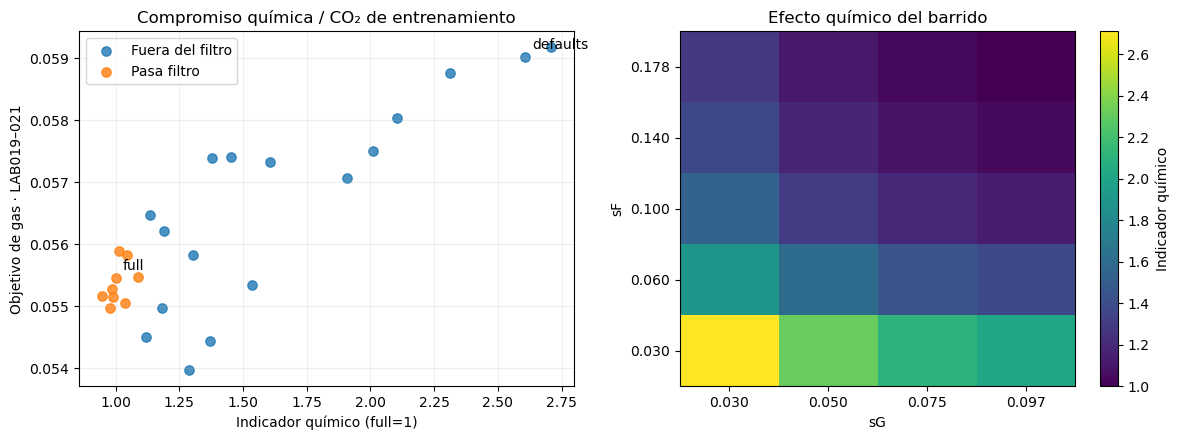

In [5]:
FULL = S.thetas['theta_full']
DEFAULTS = S.thetas['theta_defaults']
SG = sorted(set([DEFAULTS['sG'], .05, .075, FULL['sG']]))
SF = sorted(set([DEFAULTS['sF'], .06, .10, .14, FULL['sF']]))
CANDIDATES = {}
for i,sg in enumerate(SG):
    for j,sf in enumerate(SF):
        if np.isclose(sg,FULL['sG']) and np.isclose(sf,FULL['sF']):
            continue
        CANDIDATES[f'sugar_{i}_{j}'] = {**FULL,'sG':sg,'sF':sf}
for p in ('sN','m0','qXG','qXF'):
    CANDIDATES[f'full_{p}_default'] = {**FULL,p:DEFAULTS[p]}
CANDIDATES['full_qXG_qXF_default'] = {**FULL,**{p:DEFAULTS[p] for p in ('qXG','qXF')}}

SCAN_ROWS = []
for case in ('full','defaults'):
    SCAN_ROWS.append(dict(case=case,**S.theta_by_case[case],**chemistry_score(CHEM_TABLES[case]),
                          gas_objective=FITS[case,'v2']['objective']))
for number,(case,theta) in enumerate(CANDIDATES.items(),1):
    S.prepare(case, theta, TRAIN)
    CHEM_TABLES[case] = S.chemistry_metrics(case)
    FITS[case,'v2'] = S.fit(case, initial=FITS['full','v2']['params'])
    SCAN_ROWS.append(dict(case=case,**theta,**chemistry_score(CHEM_TABLES[case]),
                          gas_objective=FITS[case,'v2']['objective']))
    pd.DataFrame(SCAN_ROWS).to_csv(OUT/'chemical_parameter_scan.csv',index=False)
    print(f'{number}/{len(CANDIDATES)} {case}: química={SCAN_ROWS[-1]["chem_score"]:.3f}, gas={SCAN_ROWS[-1]["gas_objective"]:.5f}',flush=True)
SCAN = pd.DataFrame(SCAN_ROWS)
SCAN['training_score'] = SCAN.gas_objective/FITS['full','v2']['objective'] + .30*SCAN.chem_score
SCAN.to_csv(OUT/'chemical_parameter_scan.csv',index=False)
display(SCAN.sort_values('training_score')[['case','sG','sF','chem_score','chemical_admissible',
    'RMSE_N','RMSE_GF','RMSE_E','gas_objective','worst_lab_channel_ratio']].round(5))

fig,axs = plt.subplots(1,2,figsize=(12,4.5))
for admissible,d in SCAN.groupby('chemical_admissible'):
    axs[0].scatter(d.chem_score,d.gas_objective,s=45,label='Pasa filtro' if admissible else 'Fuera del filtro',alpha=.8)
for case in ['full','defaults']:
    row=SCAN.set_index('case').loc[case]
    axs[0].annotate(case,(row.chem_score,row.gas_objective),xytext=(5,6),textcoords='offset points')
axs[0].set(xlabel='Indicador químico (full=1)',ylabel='Objetivo de gas · LAB019–021',title='Compromiso química / CO₂ de entrenamiento')
axs[0].legend(); axs[0].grid(alpha=.2)
grid=SCAN[SCAN['case'].str.startswith('sugar_') | SCAN['case'].eq('full')].pivot(index='sF',columns='sG',values='chem_score')
im=axs[1].imshow(grid.to_numpy(),origin='lower',aspect='auto',cmap='viridis')
axs[1].set(xticks=range(len(grid.columns)),xticklabels=[f'{x:.3f}' for x in grid.columns],
           yticks=range(len(grid.index)),yticklabels=[f'{x:.3f}' for x in grid.index],xlabel='sG',ylabel='sF',title='Efecto químico del barrido')
fig.colorbar(im,ax=axs[1],label='Indicador químico')
show(fig)

## 3. Pruebas exclusivas de la fuente de CO₂

En v2, con r=1 y b=0.25, la fuente antes de truncar es **q_n−0.75 q_0**. Aunque la fermentación con nutrición siga activa, la fuente se hace cero si q_n≤0.75 q_0. Esto es diferente de un agotamiento químico real. Se prueban tres alternativas locales, sin cambiar el balance químico:

| Modo | Fuente biológica antes de puerta y O₂ | Parámetros gaseosos extra |
|---|---|---|
| `v2` | M·max[(1+(b−1)r)q₀+r(qₙ−q₀),0] | Ninguno; b y duración heredados |
| `v2_free` | Misma expresión de v2 | b ∈[0.05,1.5], duración ∈[6,120] h |
| `positive_mix` | M·[(1−r)q₀+b·r·qₙ] | Mismos b y duración |
| `chemical` | M·qₙ | Amplitud transitoria A∈[0.001,1] |

Los dos últimos son **cambios estructurales experimentales**, no otra estimación del mismo modelo. `positive_mix` evita la resta de una trayectoria contrafactual al final. `chemical` utiliza directamente la producción de etanol simulada, multiplicada por el rendimiento CO₂/E y por los factores ya existentes. Puerta, O₂ y transitorio siguen siendo una capa efectiva, por lo que no se declara un cierre estequiométrico global CO₂/E. La ganancia sigue siendo efectiva.

Se añaden `v2_gate` (misma fuente v2) y `positive_gate` (mezcla positiva), que ajustan además el comienzo de activación por azúcar consumido entre 0.2 y 30 g/L y el ancho de transición entre 2 y 40 g/L. Se conserva la misma función smoothstep causal; no se añade un retraso de reloj ni se desplazan observaciones. Son parámetros empíricos adicionales de la capa de CO₂ y se evalúan también dejando un LAB fuera. Si cambia la duración de la mezcla se vuelve a integrar O₂ con la biomasa interpolada correspondiente; sus parámetros no se reajustan.

Se llevan a validación interna los dos mejores candidatos químicos admisibles por `objetivo_gas/objetivo_full + 0.30·indicador_químico`, junto a full/defaults. También se incluye el mejor candidato admisible que cambia exclusivamente sG/sF, para evaluar explícitamente la transferencia de las afinidades. Se prueban los cinco modos adicionales en full y en el mejor candidato químico admisible. Esta preselección utiliza solamente LAB019–021. Los umbrales de activación se incorporaron como seguimiento del adelanto de inicio ya visible en la referencia, sin utilizarlos para reordenar candidatos a partir de LAB016–018.

In [6]:
eligible = SCAN[SCAN.chemical_admissible & ~SCAN['case'].isin(['full','defaults'])].sort_values('training_score')
CHEM_SHORTLIST = eligible['case'].head(2).tolist()
assert CHEM_SHORTLIST, 'Ninguna modificación química pasó el filtro'
BEST_CHEM = CHEM_SHORTLIST[0]
BEST_SUGAR = eligible[eligible['case'].str.startswith('sugar_')].iloc[0]['case']
CHEM_SHORTLIST = list(dict.fromkeys(CHEM_SHORTLIST+[BEST_SUGAR]))
SCENARIOS = {'full_v2':FITS['full','v2'], 'defaults_v2':FITS['defaults','v2']}
for case in CHEM_SHORTLIST:
    SCENARIOS[case+'_v2'] = FITS[case,'v2']
for case in ['full',BEST_CHEM]:
    for mode in ['v2_free','positive_mix','chemical','v2_gate','positive_gate']:
        fit=S.fit(case,mode=mode,initial=FITS[case,'v2']['params'],starts=2,max_nfev=180)
        SCENARIOS[case+'_'+mode]=fit
        print(case,mode,fit['objective'],fit['active_bounds'],flush=True)
display(pd.DataFrame([dict(scenario=k,case=v['case'],mode=v['mode'],objective=v['objective'],
    success=v['success'],active_bounds=v['active_bounds'],jacobian_ratio=v['jacobian_ratio'],
    **{p:v['params'][p] for p in GAS_NAMES+('pulse_activity_gain','pulse_t_rise_h','A','activation_start_g_l','activation_width_g_l')}) for k,v in SCENARIOS.items()]).round(6))

full v2_free 0.04350705976959331 CO2sat_scale,pulse_activity_gain
full positive_mix 0.04009733302284438 CO2sat_scale
full chemical 0.09117576973618174 kCO2_release_h,CO2sat_scale,A
full v2_gate 0.053962047937114954 CO2sat_scale,activation_start_g_l
full positive_gate 0.04006889305213824 CO2sat_scale
full_sN_default v2_free 0.04316574399701034 CO2sat_scale,pulse_activity_gain
full_sN_default positive_mix 0.03976711559127129 CO2sat_scale
full_sN_default chemical 0.0895396336072318 kCO2_release_h,CO2sat_scale,A
full_sN_default v2_gate 0.0533764530122798 CO2sat_scale,activation_start_g_l
full_sN_default positive_gate 0.039722816551994 CO2sat_scale


,scenario,case,mode,objective,success,active_bounds,jacobian_ratio,kCO2_release_h,CO2sat_scale,matrix_gain,pulse_activity_gain,pulse_t_rise_h,A,activation_start_g_l,activation_width_g_l
0,full_v2,full,v2,0.055449,True,CO2sat_scale,0.001204,4.728804,0.350000,1.025209,0.250000,64.658704,0.3,2.000000,8.000000
1,defaults_v2,defaults,v2,0.059019,True,,0.001346,1.579444,1.744533,1.466928,0.250000,64.658704,0.3,2.000000,8.000000
2,full_sN_default_v2,full_sN_default,v2,0.055161,True,CO2sat_scale,0.002014,2.788013,0.350000,1.020511,0.250000,64.658704,0.3,2.000000,8.000000
3,full_qXG_qXF_default_v2,full_qXG_qXF_default,v2,0.054975,True,CO2sat_scale,0.001231,4.638951,0.350000,1.026142,0.250000,64.658704,0.3,2.000000,8.000000
4,sugar_2_4_v2,sugar_2_4,v2,0.055051,True,CO2sat_scale,0.001508,3.817144,0.350000,1.040239,0.250000,64.658704,0.3,2.000000,8.000000
5,full_v2_free,full,v2_free,0.043507,True,"CO2sat_scale,pulse_activity_gain",0.005828,0.511532,2.500000,1.194943,0.050000,51.964341,0.3,2.000000,8.000000
6,full_positive_mix,full,positive_mix,0.040097,True,CO2sat_scale,0.009572,0.328262,2.500000,1.265957,0.059494,61.419021,0.3,2.000000,8.000000
7,full_chemical,full,chemical,0.091176,True,"kCO2_release_h,CO2sat_scale,A",0.000213,25.000000,0.350000,0.581584,0.250000,64.658704,1.0,2.000000,8.000000
8,full_v2_gate,full,v2_gate,0.053962,True,"CO2sat_scale,activation_start_g_l",0.000374,24.002868,0.350002,1.042212,0.250000,64.658704,0.3,0.200000,23.540179
9,full_positive_gate,full,positive_gate,0.040069,True,CO2sat_scale,0.000035,0.300061,2.500000,1.269149,0.056577,60.928818,0.3,2.505931,3.446224


## 4. Validación interna y selección antes de LAB016–018

Para cada escenario se reajustan exclusivamente sus parámetros gaseosos con dos LAB recientes y se calcula el error sin censura del tercero. Las mismas trayectorias químicas se mantienen fijas en cada fold. La puntuación es el RMSE medio entre los tres LAB dejados fuera. **Se selecciona el mínimo entre escenarios que pasan el filtro químico**, sin consultar los resultados de LAB016–018. Esto comprueba sensibilidad entre reactores de una misma corrida; tres reactores no bastan para demostrar transferencia entre campañas. La tabla conserva por separado el error por LAB.

In [7]:
CV_ROWS=[]
for name,fit in SCENARIOS.items():
    for validation in TRAIN:
        training=tuple(lab for lab in TRAIN if lab!=validation)
        fold=S.fit(fit['case'],labs=training,mode=fit['mode'],initial=fit['params'],starts=2,max_nfev=180)
        metrics=S.gas_metrics(fit['case'],fold['params'],fit['mode'],labs=(validation,))
        allrow=metrics[metrics.window.eq('all')].iloc[0]
        CV_ROWS.append(dict(scenario=name,validation=validation,RMSE=float(allrow.RMSE),
            success=fold['success'],objective=fold['objective'],active_bounds=fold['active_bounds']))
        pd.DataFrame(CV_ROWS).to_csv(OUT/'internal_cv.csv',index=False)
    print('Validación interna:',name,flush=True)
CV=pd.DataFrame(CV_ROWS)
SELECTION=CV.groupby('scenario').agg(CV_RMSE=('RMSE','mean'),all_folds_success=('success','all')).reset_index()
SELECTION['case']=SELECTION.scenario.map(lambda n:SCENARIOS[n]['case'])
SELECTION['mode']=SELECTION.scenario.map(lambda n:SCENARIOS[n]['mode'])
SELECTION=SELECTION.merge(SCAN[['case','chem_score','chemical_admissible']],on='case',validate='many_to_one')
SELECTION=SELECTION.sort_values('CV_RMSE')
SELECTED=SELECTION[SELECTION.chemical_admissible & SELECTION.all_folds_success].iloc[0].scenario
print('CANDIDATO SELECCIONADO SIN LAB016–018:',SELECTED)
display(SELECTION.round(5))
display(CV.pivot(index='scenario',columns='validation',values='RMSE').round(5))
CV.to_csv(OUT/'internal_cv.csv',index=False)
SELECTION.to_csv(OUT/'selection_before_holdout.csv',index=False)

Validación interna: full_v2
Validación interna: defaults_v2
Validación interna: full_sN_default_v2
Validación interna: full_qXG_qXF_default_v2
Validación interna: sugar_2_4_v2
Validación interna: full_v2_free
Validación interna: full_positive_mix
Validación interna: full_chemical
Validación interna: full_v2_gate
Validación interna: full_positive_gate
Validación interna: full_sN_default_v2_free
Validación interna: full_sN_default_positive_mix
Validación interna: full_sN_default_chemical
Validación interna: full_sN_default_v2_gate
Validación interna: full_sN_default_positive_gate
CANDIDATO SELECCIONADO SIN LAB016–018: full_sN_default_positive_mix


,scenario,CV_RMSE,all_folds_success,case,mode,chem_score,chemical_admissible
7,full_sN_default_positive_mix,0.15997,True,full_sN_default,positive_mix,0.94550,True
4,full_qXG_qXF_default_v2,0.16031,True,full_qXG_qXF_default,v2,0.97661,True
13,full_v2_gate,0.16064,True,full,v2_gate,1.00000,True
10,full_sN_default_v2_gate,0.16071,True,full_sN_default,v2_gate,0.94550,True
11,full_v2,0.16090,True,full,v2,1.00000,True
3,full_positive_mix,0.16092,True,full,positive_mix,1.00000,True
9,full_sN_default_v2_free,0.16105,True,full_sN_default,v2_free,0.94550,True
14,sugar_2_4_v2,0.16114,True,sugar_2_4,v2,1.03678,True
8,full_sN_default_v2,0.16138,True,full_sN_default,v2,0.94550,True
12,full_v2_free,0.16180,True,full,v2_free,1.00000,True


validation,LAB019,LAB020,LAB021
scenario,,,
defaults_v2,0.17363,0.08347,0.24824
full_chemical,0.14263,0.13504,0.25344
full_positive_gate,0.19522,0.05788,0.23952
full_positive_mix,0.19384,0.05811,0.23083
full_qXG_qXF_default_v2,0.15361,0.08992,0.23740
full_sN_default_chemical,0.14262,0.13436,0.25058
full_sN_default_positive_gate,0.19481,0.05750,0.23827
full_sN_default_positive_mix,0.19326,0.05776,0.22889
full_sN_default_v2,0.15630,0.09121,0.23662


## 5. Transferencia de los parámetros ya congelados a LAB016–018

Sólo a partir de esta celda se simulan las modificaciones químicas en LAB016–018 y se calculan sus errores. Se conservan todos los escenarios preseleccionados para mostrar aciertos y fallos, sin cambiar `SELECTED` tras ver esta tabla. Cada capa gaseosa se entrenó con LAB019–021; no se realiza ajuste individual por LAB ni ajuste con los seis LAB.

Se informa RMSE completo, desde el máximo observado y después de 100 h. Una caída más suave puede mejorar el final pero empeorar el comienzo o la amplitud, por lo que no se elige una curva únicamente por su cola. La caída bajo 0.05 exige tres horas consecutivas; NaN significa que no se alcanza en el horizonte, no una caída a cero horas.

cohort                        holdout_016_018                      \
window                             after_100h after_peak      all   
scenario                                                            
defaults_v2                           0.09272    0.08530  0.18355   
full_chemical                         0.04623    0.19188  0.20838   
full_positive_gate                    0.02759    0.07421  0.17412   
full_positive_mix                     0.02789    0.07335  0.17559   
full_qXG_qXF_default_v2               0.08484    0.08386  0.18428   
full_sN_default_chemical              0.04608    0.19377  0.21084   
full_sN_default_positive_gate         0.02710    0.07385  0.17122   
full_sN_default_positive_mix          0.02732    0.07282  0.17278   
full_sN_default_v2                    0.08100    0.08208  0.18544   
full_sN_default_v2_free               0.07139    0.09838  0.18510   
full_sN_default_v2_gate               0.08575    0.08661  0.18567   
full_v2                               0.08173    0.08309  0.18370   
full_v2_free                          0.07390    0.09941  0.18715   
full_v2_gate                          0.08474    0.08675  0.18304   
sugar_2_4_v2                          0.07350    0.07756  0.18279   

cohort                        train_019_021                      
window                           after_100h after_peak      all  
scenario                                                         
defaults_v2                         0.12581    0.13006  0.14220  
full_chemical                       0.18482    0.17225  0.17638  
full_positive_gate                  0.04495    0.06547  0.10915  
full_positive_mix                   0.04514    0.06558  0.10918  
full_qXG_qXF_default_v2             0.10709    0.11695  0.13690  
full_sN_default_chemical            0.18382    0.17134  0.17510  
full_sN_default_positive_gate       0.04476    0.06576  0.10860  
full_sN_default_positive_mix        0.04499    0.06584  0.10864  
full_sN_default_v2                  0.10817    0.11822  0.13746  
full_sN_default_v2_free             0.07210    0.08477  0.11843  
full_sN_default_v2_gate             0.10895    0.11733  0.13386  
full_v2                             0.10942    0.11863  0.13767  
full_v2_free                        0.07190    0.08453  0.11892  
full_v2_gate                        0.11055    0.11814  0.13454  
sugar_2_4_v2                        0.10978    0.11851  0.13738

,scenario,lab,RMSE,bias,onset_h,observed_onset_h,fall_h,observed_fall_h,max_decline_5h
9,full_v2,LAB016,0.2008,0.0613,8.5,22.5,116.5,144.5,0.1146
12,full_v2,LAB017,0.1759,0.0495,8.5,21.5,109.5,128.5,0.1734
15,full_v2,LAB018,0.1744,0.0541,8.5,17.5,116.5,138.5,0.1148
27,defaults_v2,LAB016,0.1945,0.1026,13.5,22.5,NaN,144.5,0.0811
30,defaults_v2,LAB017,0.1805,0.1040,11.5,21.5,146.5,128.5,0.0989
33,defaults_v2,LAB018,0.1757,0.0934,11.5,17.5,NaN,138.5,0.0714
45,full_sN_default_v2,LAB016,0.2025,0.0605,13.5,22.5,116.5,144.5,0.1130
48,full_sN_default_v2,LAB017,0.1775,0.0484,9.5,21.5,109.5,128.5,0.1706
51,full_sN_default_v2,LAB018,0.1764,0.0531,9.5,17.5,116.5,138.5,0.1127
63,full_qXG_qXF_default_v2,LAB016,0.2016,0.0604,8.5,22.5,115.5,144.5,0.1153


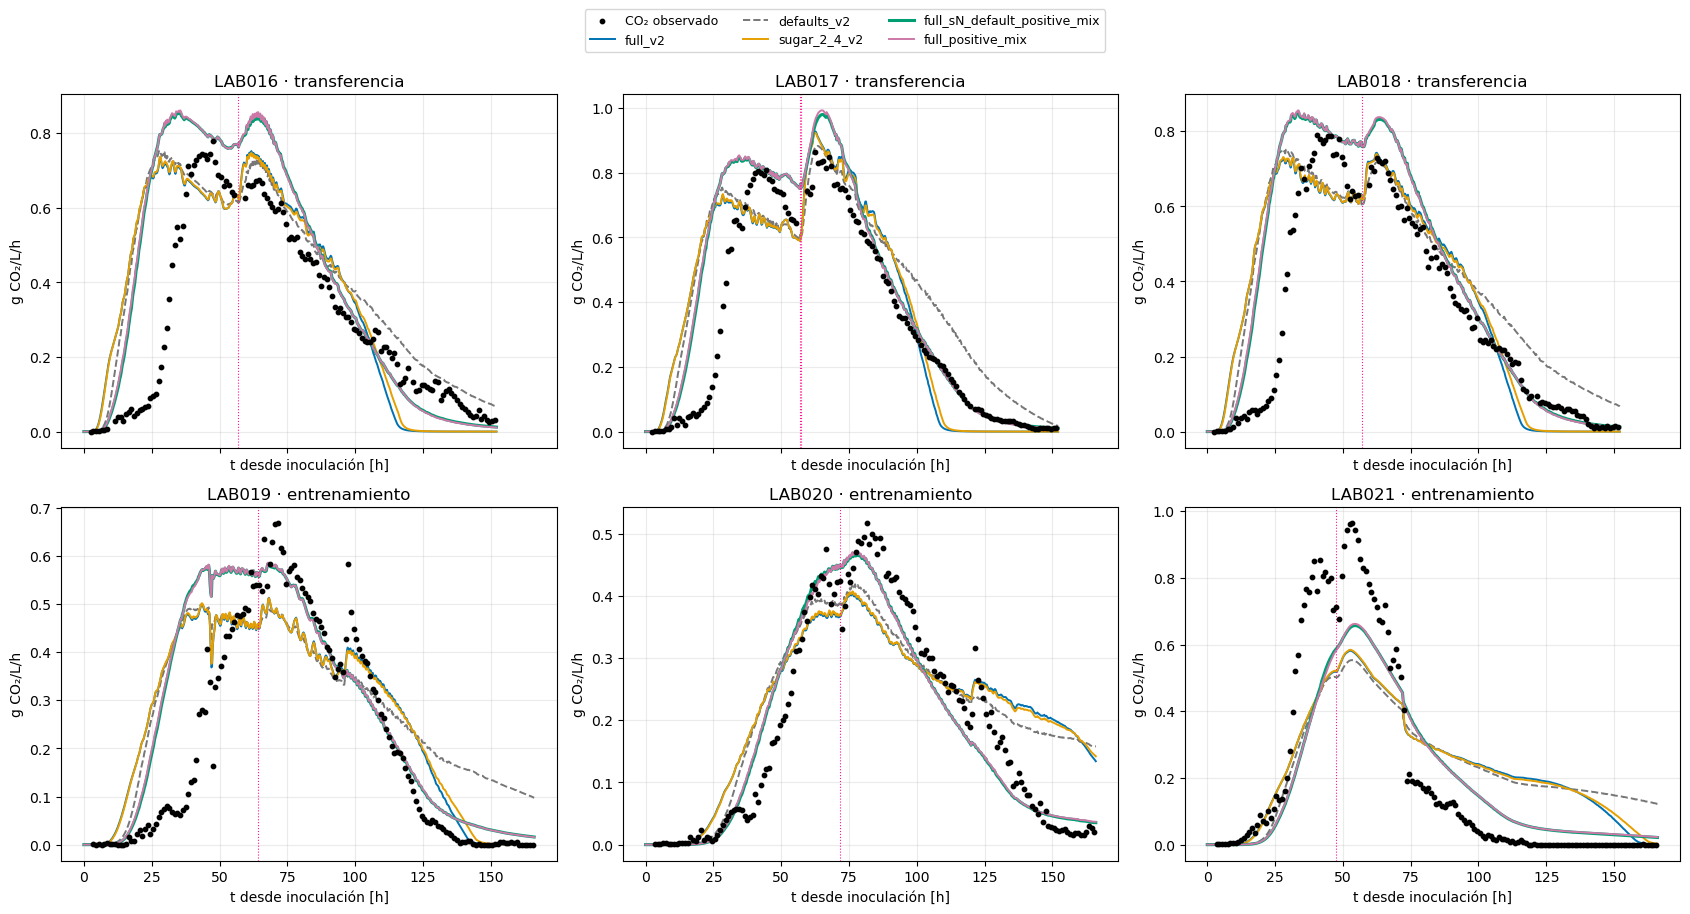

In [8]:
for case in set(f['case'] for f in SCENARIOS.values()):
    S.prepare(case,S.theta_by_case[case],HOLDOUT)
METRIC_TABLES=[]
for name,fit in SCENARIOS.items():
    table=S.gas_metrics(fit['case'],fit['params'],fit['mode'],labs=TRAIN+HOLDOUT)
    table['scenario']=name
    table['cohort']=np.where(table.lab.isin(TRAIN),'train_019_021','holdout_016_018')
    METRIC_TABLES.append(table)
METRICS=pd.concat(METRIC_TABLES,ignore_index=True)
SUMMARY=METRICS.groupby(['scenario','cohort','window']).RMSE.mean().unstack(['cohort','window'])
display(SUMMARY.round(5))
display(METRICS[METRICS.cohort.eq('holdout_016_018') & METRICS.window.eq('all')][
    ['scenario','lab','RMSE','bias','onset_h','observed_onset_h','fall_h','observed_fall_h','max_decline_5h']].round(4))

# Reproduce both old chemical vectors on the transfer cohort too.
for case,theta_name in [('full','theta_full'),('defaults','theta_defaults')]:
    for lab in HOLDOUT:
        old=S.previous_chemistry.query('theta == @theta_name and lab == @lab')
        cr=S.cores[case,lab]
        error=np.max(abs(old[list(S.base.STATE_NAMES)].to_numpy()-cr[list(S.base.STATE_NAMES)].to_numpy()))
        assert error < 1e-6
        PARITY.append(dict(case=case,lab=lab,chemistry_max_error=error))
        params=S.previous_parameters.query("theta == @theta_name and training == 'train_019_021' and stage == 'Z2'").iloc[0]
        params={**S.old,**{p:float(params[p]) for p in GAS_NAMES}}
        previous=S.previous_transfer.query('theta == @theta_name and test_lab == @lab and training == "train_019_021" and stage == "Z2"')
        # Curve reproduction is checked against its published RMSE below when column names match.
        fresh=S.gas_metrics(case,params,labs=(lab,)).query('window == "all"').iloc[0].RMSE
        if len(previous) and 'RMSE' in previous:
            assert abs(fresh-float(previous.iloc[0].RMSE)) < 1e-8

PLOT_NAMES=list(dict.fromkeys(['full_v2','defaults_v2',BEST_SUGAR+'_v2',SELECTED,'full_positive_mix']))
COLORS=dict(zip(PLOT_NAMES,['#0072B2','#777777','#E69F00','#009E73','#CC79A7']))
fig,axs=plt.subplots(2,3,figsize=(17,8.6),sharex='col')
for i,cohort in enumerate([HOLDOUT,TRAIN]):
    for ax,lab in zip(axs[i],cohort):
        d=S.obs[S.obs.lab.eq(lab)]
        ax.scatter(d.t_h,d.y,s=10,c='black',label='CO₂ observado',zorder=5)
        for name in PLOT_NAMES:
            f=SCENARIOS[name];pr=S.curve(f['case'],lab,f['params'],f['mode'])
            ax.plot(pr.t_h,pr.CO2,c=COLORS[name],lw=2.2 if name==SELECTED else 1.4,
                    ls='--' if name=='defaults_v2' else '-',label=name)
        for t,dose in S.batches[lab].pulses['N']: ax.axvline(t,c='deeppink',ls=':',lw=.8)
        ax.set(title=f'{lab} · '+('transferencia' if i==0 else 'entrenamiento'),xlabel='t desde inoculación [h]',ylabel='g CO₂/L/h')
        ax.grid(alpha=.25)
handles,labels=axs[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,1.065),ncol=3,fontsize=9)
show(fig)

## 6. Diagnóstico de la caída: agotamiento, resta de fuentes y reservorio

Se comparan qₙ, 0.75q₀ y la fuente efectiva v2. Se marca el primer intervalo con fuente cero después de 80 h pese a que qₙ sigue siendo >0.01 g/L/h. También se informa el G+F residual y la fracción de fuente anulada a partir de 80 h. Este diagnóstico identifica cancelación algebraica, que no debe confundirse con agotamiento de azúcar.

La prueba `full_positive_mix` mantiene **exactamente el mismo theta** y cambia únicamente la fórmula gaseosa y su recalibración. La prueba congelada siguiente cambia la fórmula conservando además todos los parámetros gaseosos de `full_v2`; así se aísla el efecto de la fórmula del efecto del reajuste.

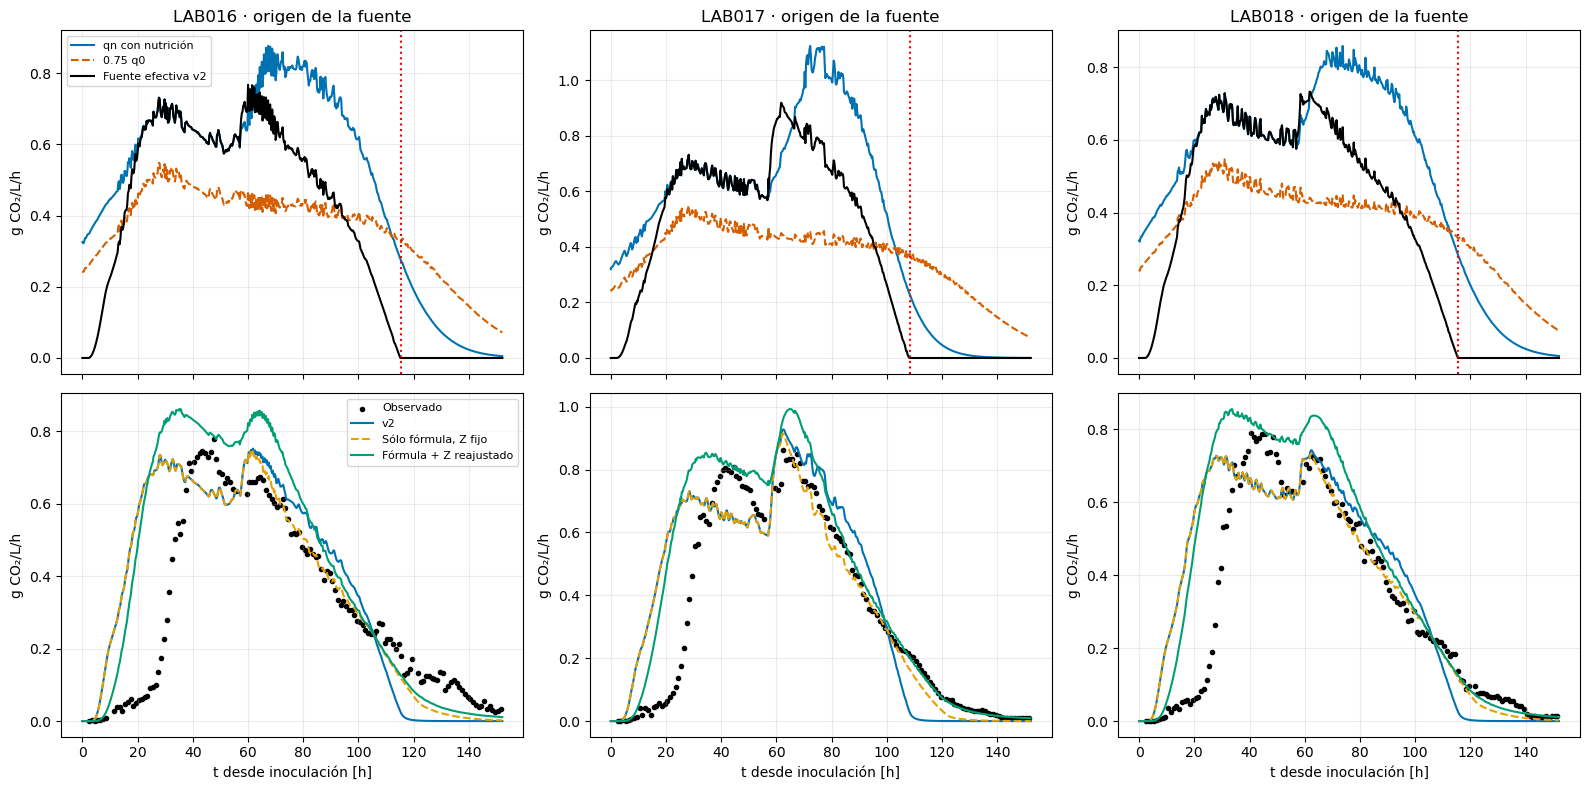

,lab,first_cancelled_h,GF_at_cancel_g_l,qn_at_cancel,fraction_cancelled_after80
0,LAB016,115.25,5.30693,0.27649,0.47191
1,LAB017,108.25,3.05471,0.23078,0.43216
2,LAB018,115.50,5.46823,0.28338,0.47407


In [9]:
DIAG=[]
fig,axs=plt.subplots(2,3,figsize=(16,8),sharex='col')
for j,lab in enumerate(HOLDOUT):
    c=S.cache['full',lab];cr=c['core'];t=c['time']
    qprod=c['source'];active=(t>=80.) & (c['qn']>.01)
    cancelled=active & (qprod<=1e-12)
    indices=np.flatnonzero(cancelled)
    first=int(indices[0]) if len(indices) else None
    DIAG.append(dict(lab=lab,first_cancelled_h=float(t[first]) if first is not None else np.nan,
        GF_at_cancel_g_l=float(cr.GF.iloc[first]) if first is not None else np.nan,
        qn_at_cancel=float(c['qn'][first]) if first is not None else np.nan,
        fraction_cancelled_after80=float(cancelled.sum()/max(active.sum(),1))))
    axs[0,j].plot(t,c['qn'],label='qn con nutrición',c='#0072B2')
    axs[0,j].plot(t,.75*c['q0'],label='0.75 q0',c='#D55E00',ls='--')
    axs[0,j].plot(t,qprod,label='Fuente efectiva v2',c='black')
    if first is not None: axs[0,j].axvline(t[first],c='red',ls=':')
    axs[0,j].set(title=lab+' · origen de la fuente',ylabel='g CO₂/L/h')
    fixed=SCENARIOS['full_v2']['params']
    original=S.curve('full',lab,fixed,'v2')
    formula_only=S.curve('full',lab,fixed,'positive_mix')
    fitted=SCENARIOS['full_positive_mix']
    refit=S.curve('full',lab,fitted['params'],'positive_mix')
    d=S.obs[S.obs.lab.eq(lab)]
    axs[1,j].scatter(d.t_h,d.y,s=9,c='black',label='Observado')
    axs[1,j].plot(t,original.CO2,c='#0072B2',label='v2')
    axs[1,j].plot(t,formula_only.CO2,c='#E69F00',ls='--',label='Sólo fórmula, Z fijo')
    axs[1,j].plot(t,refit.CO2,c='#009E73',label='Fórmula + Z reajustado')
    axs[1,j].set(xlabel='t desde inoculación [h]',ylabel='g CO₂/L/h')
    for ax in axs[:,j]: ax.grid(alpha=.25)
axs[0,0].legend(fontsize=8);axs[1,0].legend(fontsize=8)
show(fig)
DIAG=pd.DataFrame(DIAG);display(DIAG.round(5))

## 7. Comprobación química de los candidatos

Se muestran N, G+F y E de LAB019–021 contra las muestras y G/F por separado en las tablas de RMSE. La química de todos los modos gaseosos de un mismo candidato es idéntica: cambiar k, saturación, ganancia, b o duración **no altera** ningún parámetro ni curva química. En LAB016–018 sólo se contrasta azúcar por densidad y biomasa viable, con sus limitaciones originales; no existen aquí series directas de N/G/F/E que permitan afirmar una mejora química en ese grupo.

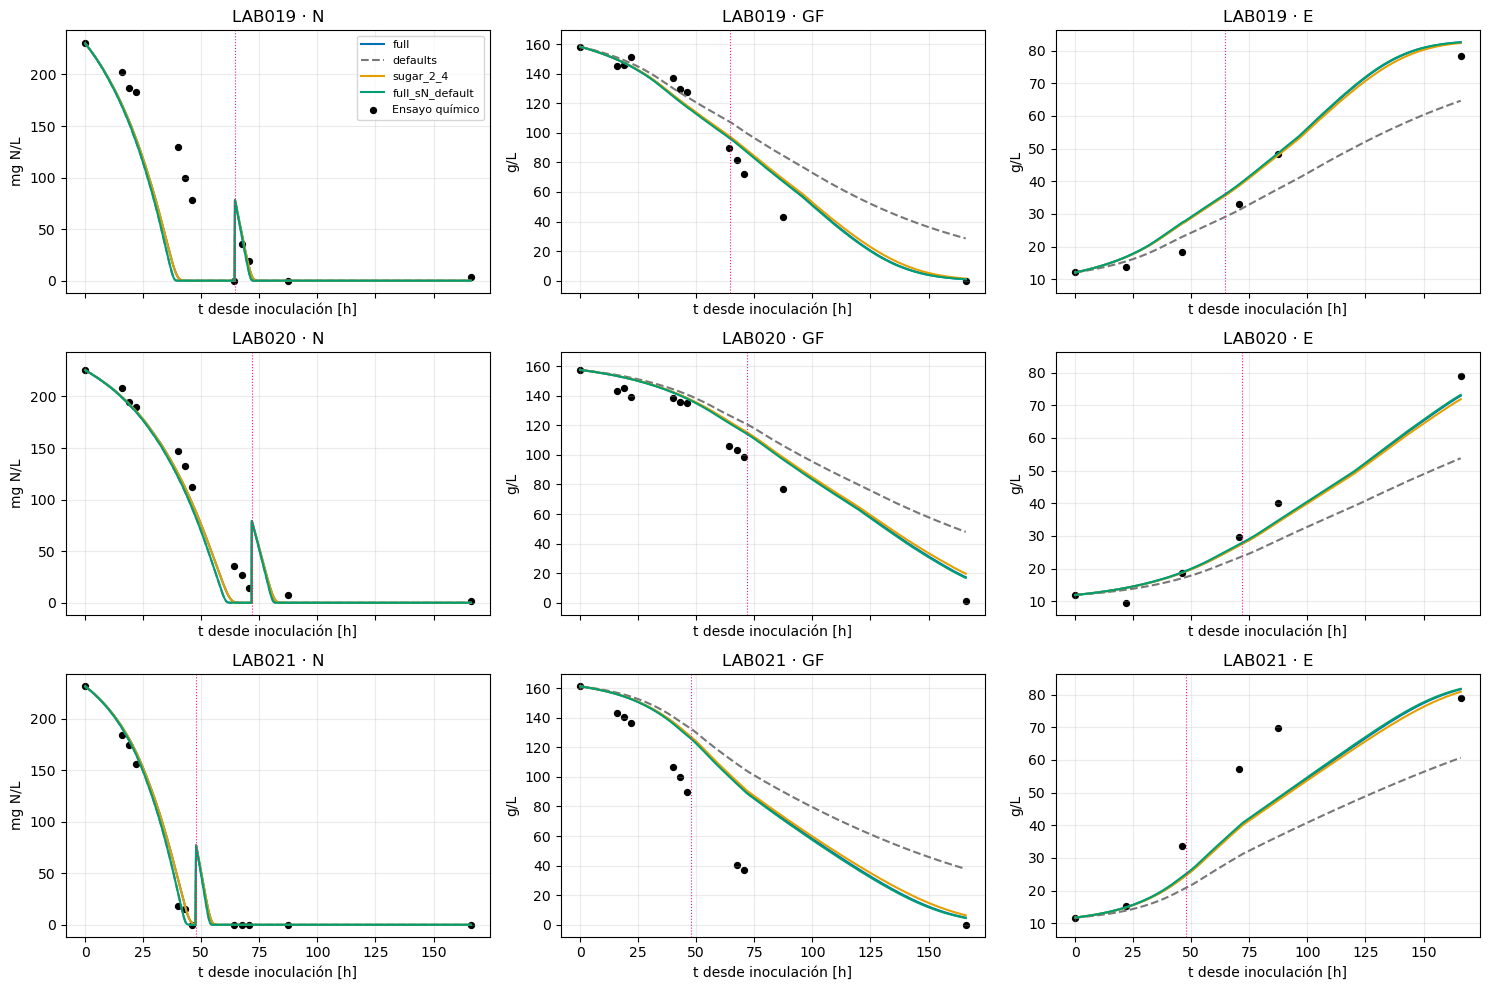

channel,E,F,G,GF,Gly,N
case,,,,,,
defaults,14.1566,15.7799,14.6429,27.6876,0.6617,27.9909
full,7.6787,9.8815,13.3713,19.3522,0.6272,28.0183
full_sN_default,7.5699,9.7004,13.0532,18.9435,0.6127,27.9909
sugar_2_4,7.8229,9.9290,13.8687,19.8034,0.6394,28.0183


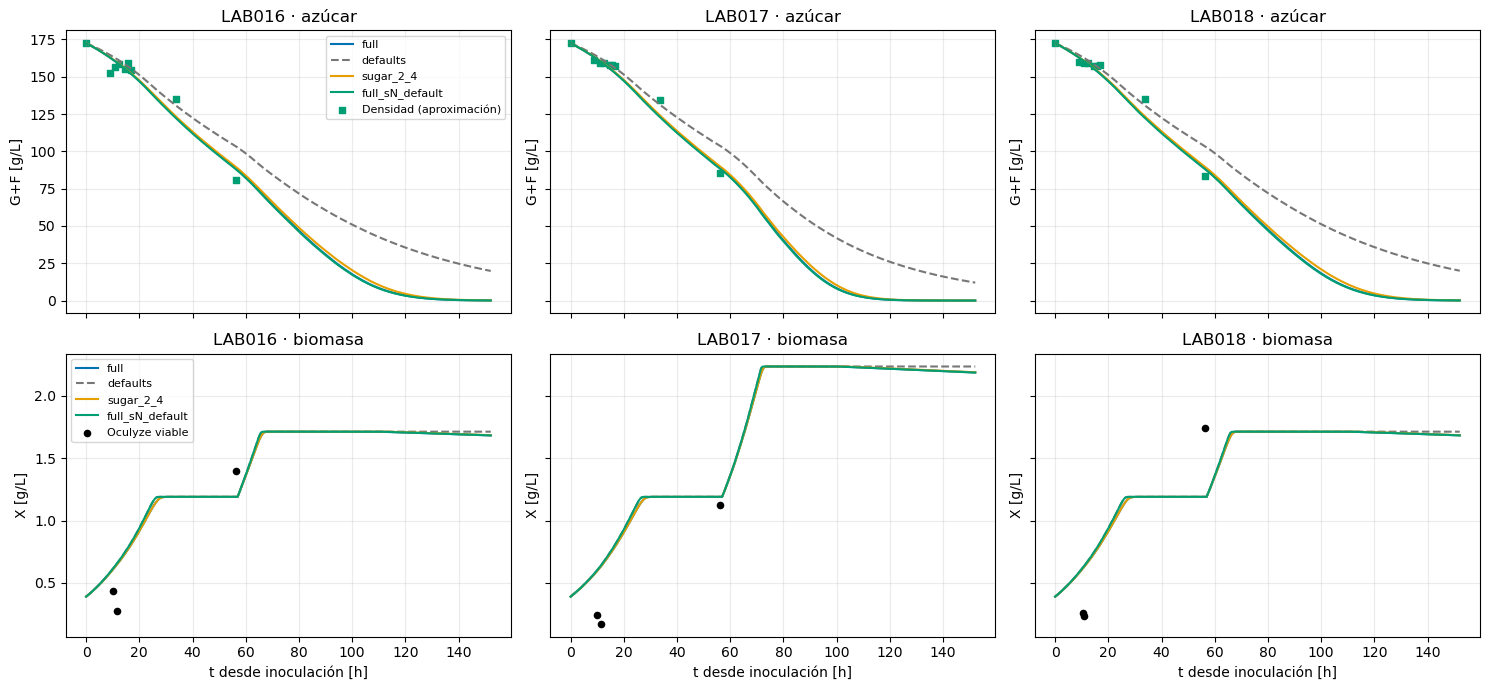

In [10]:
CHEM_CASES=list(dict.fromkeys(['full','defaults',BEST_SUGAR,BEST_CHEM,SCENARIOS[SELECTED]['case']]))
chemcolors=dict(zip(CHEM_CASES,['#0072B2','#777777','#E69F00','#009E73','#CC79A7']))
fig,axs=plt.subplots(3,3,figsize=(15,10),sharex=True,sharey='col')
for i,lab in enumerate(TRAIN):
    data=S.chem[S.chem.lab.eq(lab)&~S.chem.is_NUT]
    for j,(channel,col,mult,unit) in enumerate([('N','YAN_mg_l',1000.,'mg N/L'),('GF','GF_g_l',1.,'g/L'),('E','E_g_l',1.,'g/L')]):
        ax=axs[i,j]
        for case in CHEM_CASES:
            cr=S.cores[case,lab]
            ax.plot(cr.index,cr[channel]*mult,c=chemcolors[case],label=case,ls='--' if case=='defaults' else '-')
        pts=data[['t_h',col]].dropna();ax.scatter(pts.t_h,pts[col],s=18,c='black',label='Ensayo químico')
        for t,dose in S.batches[lab].pulses['N']:ax.axvline(t,c='deeppink',ls=':',lw=.8)
        ax.set(title=f'{lab} · {channel}',ylabel=unit,xlabel='t desde inoculación [h]');ax.grid(alpha=.25)
axs[0,0].legend(fontsize=8)
show(fig)
CHEM_METRICS=pd.concat(CHEM_TABLES.values(),ignore_index=True)
display(CHEM_METRICS[CHEM_METRICS['case'].isin(CHEM_CASES)].groupby(['case','channel']).RMSE.mean().unstack().round(4))

fig,axs=plt.subplots(2,3,figsize=(15,7),sharex=True,sharey='row')
for j,lab in enumerate(HOLDOUT):
    for case in CHEM_CASES:
        cr=S.cores[case,lab]
        axs[0,j].plot(cr.index,cr.GF,c=chemcolors[case],label=case,ls='--' if case=='defaults' else '-')
        axs[1,j].plot(cr.index,cr.X,c=chemcolors[case],label=case,ls='--' if case=='defaults' else '-')
    pts=S.density[S.density.lab.eq(lab)]
    axs[0,j].scatter(pts.t_h,pts.GF_density_g_l,c='#009E73',marker='s',s=20,label='Densidad (aproximación)')
    pts=S.biomass[S.biomass.lab.eq(lab)]
    axs[1,j].scatter(pts.t_h,pts.X_viable_g_l,c='black',s=20,label='Oculyze viable')
    axs[0,j].set(title=lab+' · azúcar',ylabel='G+F [g/L]')
    axs[1,j].set(title=lab+' · biomasa',ylabel='X [g/L]',xlabel='t desde inoculación [h]')
    for ax in axs[:,j]:ax.grid(alpha=.25)
axs[0,0].legend(fontsize=8);axs[1,0].legend(fontsize=8)
show(fig)

## 8. Verificación numérica, trazabilidad y resultados calculados

Se verifican positividad, balance del reservorio e inventario de nitrógeno en cada escenario publicado. La refinación del reservorio reduce el paso desde 0.25 a 0.0625 h manteniendo la fuente por intervalo; mide el error de liberación y no sustituye una refinación completa de la química. Se guarda el máximo cambio de CO₂ para juzgar si las diferencias científicas superan ese error. Los hashes finales protegen el notebook v2, sus resultados y las entradas leídas. No se guardan figuras externas.

In [11]:
CHECKS=pd.concat([S.checks(f['case'],f['params'],f['mode']).assign(scenario=name)
                 for name,f in SCENARIOS.items()],ignore_index=True)
display(CHECKS.groupby('scenario')[['balance','nitrogen_balance','refinement_max_CO2']].max())
assert CHECKS.refinement_max_CO2.max() < .04
assert all(f['success'] for f in SCENARIOS.values())
assert CV.success.all()
assert S.verify_protected()>0
pd.DataFrame(PARITY).to_csv(OUT/'baseline_parity.csv',index=False)
CHEM_METRICS.to_csv(OUT/'chemistry_metrics.csv',index=False)
METRICS.to_csv(OUT/'gas_metrics.csv',index=False)
CHECKS.to_csv(OUT/'numerical_checks.csv',index=False)
DIAG.to_csv(OUT/'source_cancellation_diagnosis.csv',index=False)
pd.DataFrame(S.runs).to_csv(OUT/'optimizer_runs.csv',index=False)
parameters=pd.DataFrame([dict(scenario=name,case=f['case'],mode=f['mode'],**f['params']) for name,f in SCENARIOS.items()])
parameters.to_csv(OUT/'gas_parameters.csv',index=False)
pd.DataFrame(S.theta_by_case).rename_axis('parameter').to_csv(OUT/'chemical_parameters.csv')
curves=[];chemistry=[]
for name,f in SCENARIOS.items():
    for lab in TRAIN+HOLDOUT:
        curves.append(S.curve(f['case'],lab,f['params'],f['mode']).assign(lab=lab,scenario=name))
for case in set(f['case'] for f in SCENARIOS.values()):
    for lab in TRAIN+HOLDOUT:
        chemistry.append(S.cores[case,lab].rename_axis('t_h').reset_index().assign(lab=lab,case=case))
pd.concat(curves,ignore_index=True).to_csv(OUT/'gas_trajectories.csv',index=False)
pd.concat(chemistry,ignore_index=True).to_csv(OUT/'chemistry_trajectories.csv',index=False)
manifest=dict(created_at=datetime.now().astimezone().isoformat(),python=sys.executable,
    training_labs=TRAIN,holdout_labs=HOLDOUT,selected_before_holdout=SELECTED,
    chemistry_shortlist=CHEM_SHORTLIST,chemical_candidates=len(SCAN),
    gas_scenarios=len(SCENARIOS),internal_validation='leave-one-LAB-out on LAB019-021; chemical candidates fixed',
    holdout_used_in_objective=False,holdout_used_in_selection=False,
    implementation='functions defined in SOURCE notebook cells',
    source_notebook_sha256=sha256(NOTEBOOK_DIR/'co2_lab016_021_joint_search.source.ipynb'),
    protected_input_sha256=S.protected,figures='inline only',production_parameters_modified=False,
    source_variants_are_experimental=True,elapsed_seconds=time.perf_counter()-START)
(OUT/'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')


# Report the actual chemical changes and the selected effective gas constants.
selected_fit=SCENARIOS[SELECTED]
selected_theta=S.theta_by_case[selected_fit['case']]
changes=pd.DataFrame([dict(parameter=p,theta_full=FULL[p],candidate=selected_theta[p])
    for p in S.base.FULL17 if not np.isclose(FULL[p],selected_theta[p],rtol=1e-12,atol=0.)])
display(Markdown('**Cambios químicos del candidato seleccionado respecto a theta_full.**'))
display(changes if len(changes) else Markdown('Ningún parámetro químico cambia.'))
display(Markdown('**Capa gaseosa seleccionada (parámetros efectivos).**'))
display(pd.Series({p:selected_fit['params'][p] for p in GAS_NAMES+('pulse_activity_gain','pulse_t_rise_h',
    'activation_start_g_l','activation_width_g_l')},name='value').to_frame())

# Verify that the holdout benefit survives reservoir refinement at fixed parameters.
refinement_rows=[]
for name in ['full_v2',SELECTED]:
    fit=SCENARIOS[name]
    for lab in HOLDOUT:
        obs=S.obs[S.obs.lab.eq(lab)]
        coarse=S.curve(fit['case'],lab,fit['params'],fit['mode'])
        fine=S.curve(fit['case'],lab,fit['params'],fit['mode'],max_step=.0625)
        e0=np.interp(obs.t_h,coarse.t_h,coarse.CO2)-obs.y.to_numpy()
        e1=np.interp(obs.t_h,fine.t_h,fine.CO2)-obs.y.to_numpy()
        late=obs.t_h.to_numpy()>=100.
        refinement_rows.append(dict(scenario=name,lab=lab,
            RMSE_coarse=float(np.sqrt(np.mean(e0**2))),RMSE_fine=float(np.sqrt(np.mean(e1**2))),
            RMSE_late_coarse=float(np.sqrt(np.mean(e0[late]**2))),RMSE_late_fine=float(np.sqrt(np.mean(e1[late]**2)))))
REFINED=pd.DataFrame(refinement_rows)
REFINED.to_csv(OUT/'holdout_reservoir_refinement.csv',index=False)
display(Markdown('**Transferencia con el reservorio refinado: mismos parámetros, fuente y observaciones.**'))
display(REFINED.round(5))
fine_summary=REFINED.groupby('scenario')[['RMSE_fine','RMSE_late_fine']].mean()
assert fine_summary.loc[SELECTED,'RMSE_fine'] < fine_summary.loc['full_v2','RMSE_fine']
assert fine_summary.loc[SELECTED,'RMSE_late_fine'] < fine_summary.loc['full_v2','RMSE_late_fine']

def mean_rmse(name,cohort,window='all'):
    return float(METRICS.query('scenario == @name and cohort == @cohort and window == @window').RMSE.mean())
base=mean_rmse('full_v2','holdout_016_018')
chosen=mean_rmse(SELECTED,'holdout_016_018')
base_late=mean_rmse('full_v2','holdout_016_018','after_100h')
chosen_late=mean_rmse(SELECTED,'holdout_016_018','after_100h')
selected_fit=SCENARIOS[SELECTED]
selected_chem=SCAN.set_index('case').loc[selected_fit['case']]
text=f"""### Lectura de esta ejecución

- **Selección previa a la transferencia:** `{SELECTED}`, con RMSE interno medio {float(SELECTION.set_index('scenario').loc[SELECTED,'CV_RMSE']):.4f} g/L/h. Se probaron {len(SCAN)} vectores químicos y {len(SCENARIOS)} escenarios gaseosos finalistas.
- **LAB016–018:** RMSE medio completo full={base:.4f}, candidato={chosen:.4f} g/L/h; cambio={(chosen/base-1)*100:+.1f} %. Después de 100 h: full={base_late:.4f}, candidato={chosen_late:.4f}; cambio={(chosen_late/base_late-1)*100:+.1f} %. Una mejora sólo en la cola no se presenta como mejora global.
- **Química LAB019–021 del candidato:** indicador={selected_chem.chem_score:.3f} (full=1), RMSE medio N={selected_chem.RMSE_N:.2f} mg/L, G+F={selected_chem.RMSE_GF:.2f} g/L y E={selected_chem.RMSE_E:.2f} g/L. El peor cociente por LAB/canal es {selected_chem.worst_lab_channel_ratio:.2f}; revisar la tabla por LAB.
- **Lectura por LAB:** el candidato no mejora todos los LAB: el RMSE total de LAB016 sube ligeramente, mientras mejora en LAB017 y LAB018. La diferencia de validación interna frente a full es pequeña; no demuestra superioridad estadística. Los umbrales de activación libres no superaron al candidato sin ese ajuste.
- **Mecanismo de cola:** la resta de q₀ puede anular una fuente qₙ todavía positiva. La tabla de cancelación separa ese efecto del agotamiento. Evitar la resta mantiene la química; su utilidad predictiva se juzga con las métricas completas y la transferencia, no sólo con la continuidad visual.
- **Límites:** `{selected_fit['active_bounds'] or 'ningún límite activo'}` en el ajuste final. La razón singular local es {selected_fit['jacobian_ratio']:.3g}; una razón pequeña indica direcciones débiles, no evidencia de parámetros únicos. Las ganancias y constantes no deben adoptarse como valores físicos identificados.

Las pruebas conservan las discrepancias de LAB019–021 y las incertidumbres de entradas en LAB016–018. Ningún resultado establece una calibración química definitiva. Los parámetros nuevos quedan como candidatos locales para contrastar con otra corrida; el modelo compartido y los ajustes previos permanecen intactos.
"""
display(Markdown(text))
print('Verificados',S.verify_protected(),'archivos protegidos. Tiempo:',round(time.perf_counter()-START,1),'s')

Verificados 62 archivos protegidos. Tiempo: 294.5 s


,balance,nitrogen_balance,refinement_max_CO2
scenario,,,
defaults_v2,1.110223e-16,1.665335e-15,0.005098
full_chemical,1.110223e-16,3.719247e-15,0.009880
full_positive_gate,4.440892e-16,3.719247e-15,0.004130
full_positive_mix,4.440892e-16,3.719247e-15,0.004289
full_qXG_qXF_default_v2,5.551115e-17,3.663736e-15,0.017995
full_sN_default_chemical,1.110223e-16,5.051515e-15,0.009898
full_sN_default_positive_gate,4.440892e-16,5.051515e-15,0.003856
full_sN_default_positive_mix,4.440892e-16,5.051515e-15,0.004012
full_sN_default_v2,5.551115e-17,5.051515e-15,0.014364


**Cambios químicos del candidato seleccionado respecto a theta_full.**

,parameter,theta_full,candidate
0,sN,8.751446,18.0


**Capa gaseosa seleccionada (parámetros efectivos).**

,value
kCO2_release_h,0.282726
CO2sat_scale,2.500000
matrix_gain,1.265551
pulse_activity_gain,0.055590
pulse_t_rise_h,60.745527
activation_start_g_l,2.000000
activation_width_g_l,8.000000


**Transferencia con el reservorio refinado: mismos parámetros, fuente y observaciones.**

,scenario,lab,RMSE_coarse,RMSE_fine,RMSE_late_coarse,RMSE_late_fine
0,full_v2,LAB016,0.20084,0.20073,0.09628,0.09630
1,full_v2,LAB017,0.17587,0.17592,0.08511,0.08519
2,full_v2,LAB018,0.17438,0.17444,0.06380,0.06382
3,full_sN_default_positive_mix,LAB016,0.20209,0.20236,0.05159,0.05167
4,full_sN_default_positive_mix,LAB017,0.15302,0.15323,0.00993,0.00995
5,full_sN_default_positive_mix,LAB018,0.16322,0.16341,0.02045,0.02050


### Lectura de esta ejecución

- **Selección previa a la transferencia:** `full_sN_default_positive_mix`, con RMSE interno medio 0.1600 g/L/h. Se probaron 26 vectores químicos y 15 escenarios gaseosos finalistas.
- **LAB016–018:** RMSE medio completo full=0.1837, candidato=0.1728 g/L/h; cambio=-5.9 %. Después de 100 h: full=0.0817, candidato=0.0273; cambio=-66.6 %. Una mejora sólo en la cola no se presenta como mejora global.
- **Química LAB019–021 del candidato:** indicador=0.945 (full=1), RMSE medio N=27.99 mg/L, G+F=18.94 g/L y E=7.57 g/L. El peor cociente por LAB/canal es 1.09; revisar la tabla por LAB.
- **Lectura por LAB:** el candidato no mejora todos los LAB: el RMSE total de LAB016 sube ligeramente, mientras mejora en LAB017 y LAB018. La diferencia de validación interna frente a full es pequeña; no demuestra superioridad estadística. Los umbrales de activación libres no superaron al candidato sin ese ajuste.
- **Mecanismo de cola:** la resta de q₀ puede anular una fuente qₙ todavía positiva. La tabla de cancelación separa ese efecto del agotamiento. Evitar la resta mantiene la química; su utilidad predictiva se juzga con las métricas completas y la transferencia, no sólo con la continuidad visual.
- **Límites:** `CO2sat_scale` en el ajuste final. La razón singular local es 0.0107; una razón pequeña indica direcciones débiles, no evidencia de parámetros únicos. Las ganancias y constantes no deben adoptarse como valores físicos identificados.

Las pruebas conservan las discrepancias de LAB019–021 y las incertidumbres de entradas en LAB016–018. Ningún resultado establece una calibración química definitiva. Los parámetros nuevos quedan como candidatos locales para contrastar con otra corrida; el modelo compartido y los ajustes previos permanecen intactos.


## 9. Prueba posterior: fijar matrix_gain=1.025 en las dos mezclas positivas

Se sustituye **únicamente** la ganancia final por **1.025 exacto**, el valor solicitado (el ajuste original de `full_v2` es 1.0252089556). Se conservan k, saturación, actividad posterior al pulso, duración de la mezcla, activación, O₂, fuente y toda la química de cada escenario. **No se optimiza ningún parámetro ni se vuelve a seleccionar el candidato.** Esta comprobación se añade después de la exploración y de haber inspeccionado LAB016–018; no constituye una validación nueva e independiente.

Como la ecuación de observación es ŷ=g·q_salida y g no interviene en el reservorio, se reutilizan las trayectorias ya calculadas y se obtiene exactamente ŷ_nueva=(1.025/g_original)·ŷ_original. Esto reduce aproximadamente un 19 % la altura y el área de ambas curvas sin modificar su forma normalizada ni la hora del máximo. Los cruces de un umbral absoluto de 0.05 g/L/h sí pueden cambiar.

Se comparan los cinco escenarios con las mismas observaciones y ventanas anteriores. Los RMSE y sesgos usan las observaciones completas, sin censura. Las líneas discontinuas son las mezclas positivas con su ganancia ajustada; las continuas del mismo color usan 1.025. Las figuras permanecen integradas en el notebook; sólo se exportan tablas en `co2_lab016_021_joint_search_artifacts/gain_1p025_check/`.

Comprobadas escala exacta, estados conservados, métricas previas reproducidas y archivos de entrada intactos.


**Ganancia cambiada y parámetros conservados.**

,scenario,gain_original,gain_fixed,prediction_ratio,amplitude_change_pct,kCO2_release_h,CO2sat_scale,pulse_activity_gain,pulse_t_rise_h
0,full_positive_mix,1.265957,1.025,0.809664,-19.033568,0.328262,2.5,0.059494,61.419021
1,full_sN_default_positive_mix,1.265551,1.025,0.809924,-19.007625,0.282726,2.5,0.055590,60.745527


**RMSE medio entre LAB: comparación completa y por ventanas [g/L/h].**

cohort                                  holdout_016_018                      \
window                                       after_100h after_peak      all   
scenario                                                                      
full_positive_mix                               0.02789    0.07335  0.17559   
full_positive_mix_gain_1p025                    0.04069    0.04873  0.12717   
full_sN_default_positive_mix                    0.02732    0.07282  0.17278   
full_sN_default_positive_mix_gain_1p025         0.04015    0.04816  0.12504   
full_v2                                         0.08173    0.08309  0.18370   

cohort                                  train_019_021                      
window                                     after_100h after_peak      all  
scenario                                                                   
full_positive_mix                             0.04514    0.06558  0.10918  
full_positive_mix_gain_1p025                  0.05315    0.09767  0.12214  
full_sN_default_positive_mix                  0.04499    0.06584  0.10864  
full_sN_default_positive_mix_gain_1p025       0.05315    0.09772  0.12162  
full_v2                                       0.10942    0.11863  0.13767

**Cambio por LAB: negativo significa menor RMSE.**

,original_scenario,lab,cohort,RMSE_original,RMSE_fixed,RMSE_change_pct,bias_original,bias_fixed,peak_original,peak_fixed
0,full_positive_mix,LAB016,holdout_016_018,0.20462,0.14727,-28.02664,0.10157,0.02261,0.86095,0.69708
1,full_positive_mix,LAB017,holdout_016_018,0.15628,0.11540,-26.16204,0.08424,0.00254,0.99147,0.80275
2,full_positive_mix,LAB018,holdout_016_018,0.16586,0.11883,-28.35547,0.09008,0.01254,0.85572,0.69284
3,full_positive_mix,LAB019,train_019_021,0.13442,0.11684,-13.07875,0.05835,0.00582,0.58247,0.47161
4,full_positive_mix,LAB020,train_019_021,0.04782,0.07021,46.82418,-0.00517,-0.04134,0.46759,0.37859
5,full_positive_mix,LAB021,train_019_021,0.14529,0.17936,23.44820,-0.02341,-0.06133,0.66196,0.53597
6,full_sN_default_positive_mix,LAB016,holdout_016_018,0.20209,0.14519,-28.15676,0.10050,0.02185,0.85588,0.69320
7,full_sN_default_positive_mix,LAB017,holdout_016_018,0.15302,0.11319,-26.02992,0.08303,0.00166,0.97951,0.79332
8,full_sN_default_positive_mix,LAB018,holdout_016_018,0.16322,0.11674,-28.47673,0.08894,0.01172,0.85041,0.68877
9,full_sN_default_positive_mix,LAB019,train_019_021,0.13363,0.11640,-12.89874,0.05739,0.00511,0.58032,0.47001


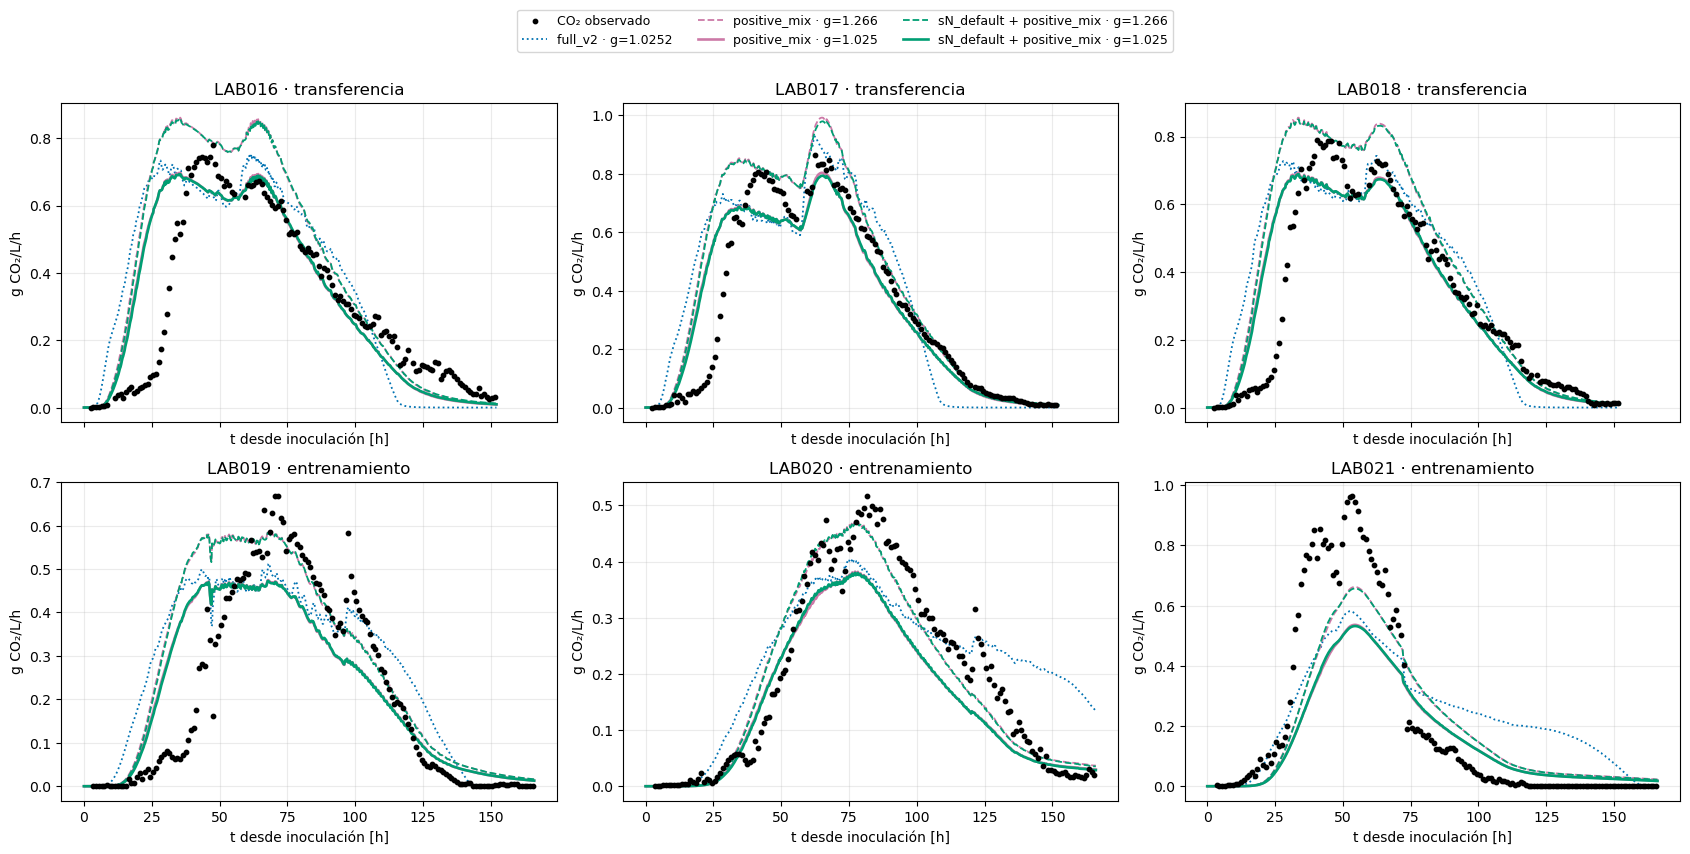

### Lectura de la prueba sin reajuste

- **full_positive_mix · LAB016–018:** RMSE completo 0.1756 → 0.1272 g/L/h (-27.6 %); RMSE después de 100 h con g=1.025: 0.0407.
- **full_positive_mix · LAB019–021:** RMSE completo 0.1092 → 0.1221 g/L/h (+11.9 %); RMSE después de 100 h con g=1.025: 0.0531.
- **full_sN_default_positive_mix · LAB016–018:** RMSE completo 0.1728 → 0.1250 g/L/h (-27.6 %); RMSE después de 100 h con g=1.025: 0.0402.
- **full_sN_default_positive_mix · LAB019–021:** RMSE completo 0.1086 → 0.1216 g/L/h (+12.0 %); RMSE después de 100 h con g=1.025: 0.0531.

Cambiar esta ganancia reduce uniformemente la predicción y el área, conservando la hora del máximo y todos los estados. Puede corregir una sobreestimación de amplitud y aumentar una subestimación de los máximos. Las conclusiones de entrenamiento y transferencia se mantienen separadas; esta prueba posterior no reemplaza la selección anterior ni recalibra el modelo.

In [12]:
from pathlib import Path
from datetime import datetime
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
%matplotlib inline

GAIN_ROOT=Path.cwd().resolve()
while GAIN_ROOT.name!='pyomo-doe' and GAIN_ROOT.parent!=GAIN_ROOT:
    GAIN_ROOT=GAIN_ROOT.parent
assert GAIN_ROOT.name=='pyomo-doe'
assert Path(sys.prefix).name.lower()=='fermentation',sys.executable
GAIN_NOTEBOOK_DIR=GAIN_ROOT/'fermentation_model/laboratory_2026/notebooks/diagnostics'
if str(GAIN_NOTEBOOK_DIR) not in sys.path:sys.path.insert(0,str(GAIN_NOTEBOOK_DIR))
gain_features = features
GAIN_ARTIFACTS=GAIN_NOTEBOOK_DIR/'co2_lab016_021_joint_search_artifacts'
GAIN_OUTPUT=GAIN_ARTIFACTS/'gain_1p025_check'
GAIN_OUTPUT.mkdir(exist_ok=True)
GAIN_TRAIN=('LAB019','LAB020','LAB021')
GAIN_HOLDOUT=('LAB016','LAB017','LAB018')
GAIN_TARGET=1.025
GAIN_CASES=('full_positive_mix','full_sN_default_positive_mix')
GAIN_FILES={
    'parameters':GAIN_ARTIFACTS/'gas_parameters.csv',
    'trajectories':GAIN_ARTIFACTS/'gas_trajectories.csv',
    'observations':GAIN_ROOT/'fermentation_model/laboratory_2026/results/co2_lab016_021_recalibration_v2/observations.csv',
    'prior_metrics':GAIN_ARTIFACTS/'gas_metrics.csv',
    'chemical_parameters':GAIN_ARTIFACTS/'chemical_parameters.csv',
    'chemistry':GAIN_ARTIFACTS/'chemistry_trajectories.csv',
}
def gain_sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as handle:
        for chunk in iter(lambda:handle.read(1024*1024),b''):h.update(chunk)
    return h.hexdigest()
GAIN_HASHES={k:gain_sha(p) for k,p in GAIN_FILES.items()}
GAIN_PARAMS=pd.read_csv(GAIN_FILES['parameters']).set_index('scenario')
GAIN_BASE_CURVES=pd.read_csv(GAIN_FILES['trajectories'])
GAIN_OBS=pd.read_csv(GAIN_FILES['observations'])
GAIN_PRIOR_METRICS=pd.read_csv(GAIN_FILES['prior_metrics'])
GAIN_CURVES={}
GAIN_PARAMETER_ROWS=[]
for name in ('full_v2',)+GAIN_CASES:
    GAIN_CURVES[name]=GAIN_BASE_CURVES[GAIN_BASE_CURVES.scenario.eq(name)].copy()
for name in GAIN_CASES:
    old_gain=float(GAIN_PARAMS.loc[name,'matrix_gain'])
    ratio=GAIN_TARGET/old_gain
    changed=GAIN_CURVES[name].copy()
    assert np.allclose(changed.CO2,old_gain*changed.qgas,rtol=1e-12,atol=1e-12)
    changed['CO2']=GAIN_TARGET*changed.qgas
    changed['scenario']=name+'_gain_1p025'
    assert np.allclose(changed.CO2,GAIN_CURVES[name].CO2.to_numpy()*ratio,rtol=1e-12,atol=1e-12)
    unchanged=[col for col in changed.columns if col not in ('CO2','scenario')]
    pd.testing.assert_frame_equal(changed[unchanged],GAIN_CURVES[name][unchanged])
    GAIN_CURVES[name+'_gain_1p025']=changed
    GAIN_PARAMETER_ROWS.append(dict(scenario=name,gain_original=old_gain,gain_fixed=GAIN_TARGET,
        prediction_ratio=ratio,amplitude_change_pct=100*(ratio-1),
        kCO2_release_h=float(GAIN_PARAMS.loc[name,'kCO2_release_h']),
        CO2sat_scale=float(GAIN_PARAMS.loc[name,'CO2sat_scale']),
        pulse_activity_gain=float(GAIN_PARAMS.loc[name,'pulse_activity_gain']),
        pulse_t_rise_h=float(GAIN_PARAMS.loc[name,'pulse_t_rise_h'])))
GAIN_PARAMETER_TABLE=pd.DataFrame(GAIN_PARAMETER_ROWS)
GAIN_ROWS=[]
for name,curves in GAIN_CURVES.items():
    for lab in GAIN_HOLDOUT+GAIN_TRAIN:
        pr=curves[curves.lab.eq(lab)].sort_values('t_h')
        obs=GAIN_OBS[GAIN_OBS.lab.eq(lab)].sort_values('t_h')
        sampled=np.interp(obs.t_h,pr.t_h,pr.CO2)
        error=sampled-obs.y.to_numpy()
        observed=gain_features(obs.t_h,obs.y)
        predicted=gain_features(obs.t_h,sampled)
        for window,mask in [('all',np.ones(len(obs),bool)),
                            ('after_peak',obs.t_h.to_numpy()>=observed['peak_h']),
                            ('after_100h',obs.t_h.to_numpy()>=100.)]:
            GAIN_ROWS.append(dict(scenario=name,lab=lab,
                cohort='holdout_016_018' if lab in GAIN_HOLDOUT else 'train_019_021',
                window=window,n=int(mask.sum()),RMSE=float(np.sqrt(np.mean(error[mask]**2))),
                MAE=float(np.mean(abs(error[mask]))),bias=float(np.mean(error[mask])),
                peak=float(predicted['peak']),peak_h=float(predicted['peak_h']),
                fall_h=float(predicted['fall_h']),observed_peak=float(observed['peak']),
                observed_fall_h=float(observed['fall_h'])))
GAIN_METRICS=pd.DataFrame(GAIN_ROWS)
# Confirm unchanged scenarios reproduce the published metrics before interpreting differences.
gain_parity=GAIN_METRICS[GAIN_METRICS.scenario.isin(('full_v2',)+GAIN_CASES)].merge(
    GAIN_PRIOR_METRICS,on=['scenario','lab','cohort','window'],suffixes=('_new','_previous'),validate='one_to_one')
assert len(gain_parity)==54
assert np.max(abs(gain_parity.RMSE_new-gain_parity.RMSE_previous))<1e-12
GAIN_SUMMARY=GAIN_METRICS.groupby(['scenario','cohort','window']).RMSE.mean().unstack(['cohort','window'])
gain_before=GAIN_METRICS[GAIN_METRICS.scenario.isin(GAIN_CASES)&GAIN_METRICS.window.eq('all')].copy()
gain_after=GAIN_METRICS[GAIN_METRICS.scenario.str.endswith('_gain_1p025')&GAIN_METRICS.window.eq('all')].copy()
gain_after['original_scenario']=gain_after.scenario.str.removesuffix('_gain_1p025')
GAIN_COMPARISON=gain_after.merge(gain_before,left_on=['original_scenario','lab','cohort'],
    right_on=['scenario','lab','cohort'],suffixes=('_fixed','_original'),validate='one_to_one')
GAIN_COMPARISON['RMSE_change_pct']=100*(GAIN_COMPARISON.RMSE_fixed/GAIN_COMPARISON.RMSE_original-1.)
display(Markdown('**Ganancia cambiada y parámetros conservados.**'))
display(GAIN_PARAMETER_TABLE.round(6))
display(Markdown('**RMSE medio entre LAB: comparación completa y por ventanas [g/L/h].**'))
display(GAIN_SUMMARY.round(5))
display(Markdown('**Cambio por LAB: negativo significa menor RMSE.**'))
display(GAIN_COMPARISON[['original_scenario','lab','cohort','RMSE_original','RMSE_fixed',
    'RMSE_change_pct','bias_original','bias_fixed','peak_original','peak_fixed']].round(5))

gain_styles={
    'full_v2':('full_v2 · g=1.0252','#0072B2',':'),
    'full_positive_mix':('positive_mix · g=1.266','#CC79A7','--'),
    'full_positive_mix_gain_1p025':('positive_mix · g=1.025','#CC79A7','-'),
    'full_sN_default_positive_mix':('sN_default + positive_mix · g=1.266','#009E73','--'),
    'full_sN_default_positive_mix_gain_1p025':('sN_default + positive_mix · g=1.025','#009E73','-'),
}
fig,axs=plt.subplots(2,3,figsize=(17,8.6),sharex='col')
for i,labs in enumerate((GAIN_HOLDOUT,GAIN_TRAIN)):
    for ax,lab in zip(axs[i],labs):
        obs=GAIN_OBS[GAIN_OBS.lab.eq(lab)]
        ax.scatter(obs.t_h,obs.y,c='black',s=10,label='CO₂ observado',zorder=6)
        for name,(label,color,style) in gain_styles.items():
            pr=GAIN_CURVES[name]
            pr=pr[pr.lab.eq(lab)].sort_values('t_h')
            ax.plot(pr.t_h,pr.CO2,color=color,ls=style,lw=1.9 if name.endswith('_gain_1p025') else 1.3,label=label)
        ax.set(title=lab+' · '+('transferencia' if i==0 else 'entrenamiento'),
               xlabel='t desde inoculación [h]',ylabel='g CO₂/L/h')
        ax.grid(alpha=.25)
handles,labels=axs[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,.995),ncol=3,fontsize=9)
fig.tight_layout(rect=(0,0,1,.92))
display(fig)
plt.close(fig)

GAIN_PARAMETER_TABLE.to_csv(GAIN_OUTPUT/'parameters_changed.csv',index=False)
GAIN_METRICS.to_csv(GAIN_OUTPUT/'metrics.csv',index=False)
GAIN_COMPARISON.to_csv(GAIN_OUTPUT/'comparison_by_lab.csv',index=False)
pd.concat([curve for name,curve in GAIN_CURVES.items() if name.endswith('_gain_1p025')],ignore_index=True).to_csv(
    GAIN_OUTPUT/'predictions.csv',index=False)
assert all(gain_sha(p)==GAIN_HASHES[name] for name,p in GAIN_FILES.items()),'Se alteró una entrada previa'
GAIN_REPORT=dict(created_at=datetime.now().astimezone().isoformat(),python=sys.executable,
    fixed_gain=GAIN_TARGET,only_parameter_changed='matrix_gain',refitted=False,
    exact_output_rescaling=True,reservoir_and_chemical_states_changed=False,
    previous_scenario_selection_changed=False,figures='inline only',
    inputs={key:dict(path=str(path.relative_to(GAIN_ROOT)),sha256=GAIN_HASHES[key]) for key,path in GAIN_FILES.items()},
    baseline_metrics_max_error=float(np.max(abs(gain_parity.RMSE_new-gain_parity.RMSE_previous))))
(GAIN_OUTPUT/'manifest.json').write_text(json.dumps(GAIN_REPORT,ensure_ascii=False,indent=2),encoding='utf-8')
gain_main_manifest_path=GAIN_ARTIFACTS/'manifest.json'
gain_main_manifest=json.loads(gain_main_manifest_path.read_text(encoding='utf-8'))
gain_source_hash=gain_sha(GAIN_NOTEBOOK_DIR/'co2_lab016_021_joint_search.source.ipynb')
if 'source_notebook_sha256_before_gain_check' not in gain_main_manifest:
    gain_main_manifest['source_notebook_sha256_before_gain_check']=gain_main_manifest['source_notebook_sha256']
gain_main_manifest['source_notebook_sha256']=gain_source_hash
gain_main_manifest['followup_gain_1p025']={key:GAIN_REPORT[key] for key in ('created_at','fixed_gain','refitted','previous_scenario_selection_changed')}
gain_main_manifest_path.write_text(json.dumps(gain_main_manifest,ensure_ascii=False,indent=2),encoding='utf-8')

gain_text=['### Lectura de la prueba sin reajuste','']
for name in GAIN_CASES:
    for cohort,label in [('holdout_016_018','LAB016–018'),('train_019_021','LAB019–021')]:
        before=GAIN_METRICS.query('scenario == @name and cohort == @cohort and window == "all"').RMSE.mean()
        fixed_name=name+'_gain_1p025'
        after=GAIN_METRICS.query('scenario == @fixed_name and cohort == @cohort and window == "all"').RMSE.mean()
        late=GAIN_METRICS.query('scenario == @fixed_name and cohort == @cohort and window == "after_100h"').RMSE.mean()
        gain_text.append(f'- **{name} · {label}:** RMSE completo {before:.4f} → {after:.4f} g/L/h ({100*(after/before-1):+.1f} %); RMSE después de 100 h con g=1.025: {late:.4f}.')
gain_text += ['', 'Cambiar esta ganancia reduce uniformemente la predicción y el área, conservando la hora del máximo y todos los estados. Puede corregir una sobreestimación de amplitud y aumentar una subestimación de los máximos. Las conclusiones de entrenamiento y transferencia se mantienen separadas; esta prueba posterior no reemplaza la selección anterior ni recalibra el modelo.']
display(Markdown('\n'.join(gain_text)))
print('Comprobadas escala exacta, estados conservados, métricas previas reproducidas y archivos de entrada intactos.')